# Risk Analytics: SQL-to-Python Pipeline

This notebook securely connects to the `risk_analysis` MySQL database, loads the five project tables into Pandas, and validates the extraction. Passwords are never saved in this notebook.

## 1. Install packages

Run this cell once in the Jupyter environment.

In [1]:
%pip install mysql-connector-python pandas
%pip install scipy

Note: you may need to restart the kernel to use updated packages.


Note: you may need to restart the kernel to use updated packages.


## 2. Import libraries and configure the connection

The database password is read from the `MYSQL_PASSWORD` environment variable when available; otherwise, Jupyter asks for it privately. Update the host, port, database, and user only if your MySQL setup differs.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from getpass import getpass
import mysql.connector

password = getpass("Enter MySQL password: ")

conn = mysql.connector.connect(
    host="localhost",
    user="root",
    password=password,
    database="risk_analysis"
)

print("Connection established successfully!", conn.is_connected())

Connection established successfully! True


## 3. Test the connection and confirm the required tables

In [3]:
cursor = conn.cursor()
cursor.execute("SHOW TABLES")
project_tables = [row[0] for row in cursor.fetchall()]
cursor.close()
project_tables

['agent_info',
 'claim_history',
 'customer_feedback',
 'customer_master',
 'policy_details']

## 4. Load all SQL tables into Pandas DataFrames

Each DataFrame is also available by name, for example `df_customer_master` and `df_claim_history`.

In [4]:
dataframes = {}

for table in project_tables:
    query = f"SELECT * FROM `{table}`"
    dataframes[table] = pd.read_sql_query(query, conn)

df_customer_master = dataframes['customer_master']
df_agent_info = dataframes['agent_info']
df_policy_details = dataframes['policy_details']
df_claim_history = dataframes['claim_history']
df_customer_feedback = dataframes['customer_feedback']


C:\Users\lokes\AppData\Local\Temp\ipykernel_19308\543095547.py:5: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  dataframes[table] = pd.read_sql_query(query, conn)


## 5. Validate record counts and schemas

This compares the exact database row counts with the extracted DataFrame counts and displays the database column definitions.

In [5]:
display(df_customer_master)
display(df_agent_info)
display(df_policy_details)
display(df_claim_history)
display(df_customer_feedback)

,customer_id,full_name,age,gender,marital_status,occupation,region,smoking_status,pre_existing_illness,risk_score,date_joined
0,CUST10000,Yahvi Chander,18,Male,Single,Student,West,No,Yes,0.61,2020-02-02
1,CUST10001,Gautami Batta,39,Female,Divorced,Salaried,East,Yes,Yes,0.56,2020-04-17
2,CUST10002,Zehaan Randhawa,34,Male,Single,Student,North,Yes,No,0.48,2018-06-27
3,CUST10003,Aarnav Bhandari,50,Male,Married,Self-employed,South,Yes,No,0.47,2021-12-02
4,CUST10005,Tripti Parekh,20,Female,Single,Student,North,Yes,No,0.55,2022-10-25
...,...,...,...,...,...,...,...,...,...,...,...
1643,CUST12490,Chameli Raman,31,Male,Married,Self-employed,South,No,Yes,0.55,2018-10-18
1644,CUST12491,Patrick Talwar,64,Male,Married,Salaried,South,Yes,Yes,0.15,2023-06-08
1645,CUST12496,Kavya Grewal,22,Female,Married,Retired,North,Yes,No,0.66,2018-08-14
1646,CUST12497,Yasti Karan,21,Male,Divorced,Self-employed,South,No,No,1.00,2022-04-11


,agent_id,region,join_date,total_policies_sold,lapsed_policies,avg_premium_sold,fraud_association
0,AGT5000,North,2016-02-15,196,42,37018.35,8
1,AGT5001,North,2016-09-05,189,28,48370.36,5
2,AGT5002,South,2016-06-26,66,0,10489.65,3
3,AGT5003,North-East,2016-04-23,250,3,12415.84,6
4,AGT5004,South,2022-11-16,263,69,24057.14,4
...,...,...,...,...,...,...,...
295,AGT5295,East,2017-06-21,140,3,16665.09,7
296,AGT5296,Central,2020-07-22,192,29,5932.15,6
297,AGT5297,Central,2020-05-02,83,1,44193.13,3
298,AGT5298,North,2020-02-18,232,61,30842.05,6


,policy_id,customer_id,product_type,coverage_amount,annual_premium,policy_start_date,policy_end_date,agent_id,status
0,POL50001,CUST10833,Property,169869.71,27193.94,2021-07-25,2022-10-25,AGT5238,Active
1,POL50002,CUST11786,Health,546514.84,19603.44,2022-09-19,2024-04-29,AGT5008,Cancelled
2,POL50003,CUST10501,Property,944249.15,36274.58,2022-12-08,2025-04-23,AGT5118,Cancelled
3,POL50004,CUST10349,Property,209475.32,23091.58,2024-04-09,2024-07-20,AGT5090,Active
4,POL50005,CUST12296,Term,887938.35,10458.22,2022-10-08,2024-12-12,AGT5050,Lapsed
...,...,...,...,...,...,...,...,...,...
2823,POL53991,CUST10002,Property,300039.56,33337.52,2022-08-26,2023-05-26,AGT5262,Lapsed
2824,POL53994,CUST12172,Term,329263.38,13782.59,2023-11-10,2025-07-01,AGT5276,Cancelled
2825,POL53996,CUST11829,Property,139846.91,15519.76,2022-10-04,2024-01-29,AGT5207,Cancelled
2826,POL53998,CUST12139,Health,165202.48,35222.07,2021-01-12,2023-02-18,AGT5213,Cancelled


,claim_id,policy_id,claim_date,claim_amount,claim_status,claim_type,fraud_flag,days_to_process
0,CLM70003,POL51902,2022-10-10,379127.79,Pending,Theft,No,40
1,CLM70004,POL50001,2021-12-06,431984.06,Approved,Hospital,No,56
2,CLM70005,POL53707,2024-07-17,206765.82,Rejected,Death,No,39
3,CLM70006,POL53642,2024-06-12,225358.05,Approved,Accident,Yes,22
4,CLM70007,POL51744,2024-06-13,340208.27,Rejected,Theft,No,31
...,...,...,...,...,...,...,...,...
1401,CLM71991,POL50232,2024-09-22,399400.01,Rejected,Other,No,50
1402,CLM71994,POL51511,2024-01-29,109732.19,Rejected,Hospital,Yes,41
1403,CLM71997,POL51754,2024-02-13,438345.46,Approved,Accident,No,46
1404,CLM71998,POL52975,2022-03-30,373093.50,Rejected,Other,No,23


,feedback_id,customer_id,date_submitted,feedback_text,satisfaction_score,contacted_agent,referred_claim
0,FDB90000,CUST11838,2020-08-07,I'm not happy with the premium charged.,3,Yes,Yes
1,FDB90001,CUST12252,2021-01-13,I'm not happy with the premium charged.,1,No,Yes
2,FDB90002,CUST10495,2022-02-16,Smooth experience with no issues.,5,No,Yes
3,FDB90003,CUST11182,2021-02-16,Claim process could be faster.,2,No,Yes
4,FDB90004,CUST11047,2021-04-09,The agent was helpful and explained everything.,5,No,No
...,...,...,...,...,...,...,...
995,FDB90995,NaN,2021-05-10,Excellent customer service support.,4,Yes,No
996,FDB90996,CUST10113,2022-06-10,Claim process could be faster.,3,Yes,No
997,FDB90997,CUST10702,2021-07-04,Claim process could be faster.,2,No,No
998,FDB90998,NaN,2021-11-20,Very satisfied with the claim process.,4,No,Yes


## 6. Validate the customer-feedback relationship

Anonymous feedback is expected to have a null `customer_id`. This check confirms that every non-null feedback customer ID exists in `customer_master`.

In [6]:
feedback_integrity_query = ('''
    SELECT
        COUNT(*) AS total_feedback,
        SUM(cf.customer_id IS NOT NULL) AS linked_feedback,
        SUM(cf.customer_id IS NULL) AS anonymous_feedback,
        SUM(cf.customer_id IS NOT NULL AND cm.customer_id IS NULL) AS invalid_customer_links
    FROM customer_feedback cf
    LEFT JOIN customer_master cm
        ON cf.customer_id = cm.customer_id
''')

feedback_integrity = pd.read_sql_query(feedback_integrity_query, conn)
display(feedback_integrity)

if feedback_integrity.loc[0, 'invalid_customer_links'] != 0:
    raise AssertionError('Invalid non-null customer IDs found in customer_feedback.')

print('Success: feedback customer links are valid; null IDs represent anonymous feedback.')

C:\Users\lokes\AppData\Local\Temp\ipykernel_19308\1589156664.py:12: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  feedback_integrity = pd.read_sql_query(feedback_integrity_query, conn)


,total_feedback,linked_feedback,anonymous_feedback,invalid_customer_links
0,1000,631.0,369.0,0.0


Success: feedback customer links are valid; null IDs represent anonymous feedback.


## 7. Importing Last File
Now importing the `data_quality_log` file directly using pandas

In [7]:
df_data_quality_log = pd.read_csv(r"C:\Users\lokes\Documents\Class\Career 247 desktop\Capstone\Main Capstone Project\Project 3 Risk Analysis\Dataset - Risk Analytics in Insurance Domain Main\Csv Files\data_quality_log.csv")

## 8. Preview Data

In [8]:
display(df_customer_master.head())
display(df_agent_info.head())
display(df_policy_details.head())
display(df_claim_history.head())
display(df_customer_feedback.head())
display(df_data_quality_log.head())

,customer_id,full_name,age,gender,marital_status,occupation,region,smoking_status,pre_existing_illness,risk_score,date_joined
0,CUST10000,Yahvi Chander,18,Male,Single,Student,West,No,Yes,0.61,2020-02-02
1,CUST10001,Gautami Batta,39,Female,Divorced,Salaried,East,Yes,Yes,0.56,2020-04-17
2,CUST10002,Zehaan Randhawa,34,Male,Single,Student,North,Yes,No,0.48,2018-06-27
3,CUST10003,Aarnav Bhandari,50,Male,Married,Self-employed,South,Yes,No,0.47,2021-12-02
4,CUST10005,Tripti Parekh,20,Female,Single,Student,North,Yes,No,0.55,2022-10-25


,agent_id,region,join_date,total_policies_sold,lapsed_policies,avg_premium_sold,fraud_association
0,AGT5000,North,2016-02-15,196,42,37018.35,8
1,AGT5001,North,2016-09-05,189,28,48370.36,5
2,AGT5002,South,2016-06-26,66,0,10489.65,3
3,AGT5003,North-East,2016-04-23,250,3,12415.84,6
4,AGT5004,South,2022-11-16,263,69,24057.14,4


,policy_id,customer_id,product_type,coverage_amount,annual_premium,policy_start_date,policy_end_date,agent_id,status
0,POL50001,CUST10833,Property,169869.71,27193.94,2021-07-25,2022-10-25,AGT5238,Active
1,POL50002,CUST11786,Health,546514.84,19603.44,2022-09-19,2024-04-29,AGT5008,Cancelled
2,POL50003,CUST10501,Property,944249.15,36274.58,2022-12-08,2025-04-23,AGT5118,Cancelled
3,POL50004,CUST10349,Property,209475.32,23091.58,2024-04-09,2024-07-20,AGT5090,Active
4,POL50005,CUST12296,Term,887938.35,10458.22,2022-10-08,2024-12-12,AGT5050,Lapsed


,claim_id,policy_id,claim_date,claim_amount,claim_status,claim_type,fraud_flag,days_to_process
0,CLM70003,POL51902,2022-10-10,379127.79,Pending,Theft,No,40
1,CLM70004,POL50001,2021-12-06,431984.06,Approved,Hospital,No,56
2,CLM70005,POL53707,2024-07-17,206765.82,Rejected,Death,No,39
3,CLM70006,POL53642,2024-06-12,225358.05,Approved,Accident,Yes,22
4,CLM70007,POL51744,2024-06-13,340208.27,Rejected,Theft,No,31


,feedback_id,customer_id,date_submitted,feedback_text,satisfaction_score,contacted_agent,referred_claim
0,FDB90000,CUST11838,2020-08-07,I'm not happy with the premium charged.,3,Yes,Yes
1,FDB90001,CUST12252,2021-01-13,I'm not happy with the premium charged.,1,No,Yes
2,FDB90002,CUST10495,2022-02-16,Smooth experience with no issues.,5,No,Yes
3,FDB90003,CUST11182,2021-02-16,Claim process could be faster.,2,No,Yes
4,FDB90004,CUST11047,2021-04-09,The agent was helpful and explained everything.,5,No,No


,worksheet_name,column,total_records,no_of_issues,error_type,error_rate,issues_resolved,Description
0,customermaster,region,1648,10,Typo Error,0.61%,Yes,Replaced error values
1,customermaster,gender,1648,17,Typo Error,1.03%,Yes,Replaced error values
2,claimhistory,status,1406,6,Typo Error,0.43%,Yes,Replaced error values
3,claimhistory,claim_date,1406,0,Data Type,0.00%,Yes,Changed Data Type to Date
4,customerfeedback,date_submitted,1000,1000,Data Type,100.00%,Yes,Changed Data Type using Text-to-column


## 9. Preparing Data For Analysis (Cleaning, Transforming and EDA)

### Cleaning Tables & Creating New Columns in Tables

In [9]:
df_customer_master

,customer_id,full_name,age,gender,marital_status,occupation,region,smoking_status,pre_existing_illness,risk_score,date_joined
0,CUST10000,Yahvi Chander,18,Male,Single,Student,West,No,Yes,0.61,2020-02-02
1,CUST10001,Gautami Batta,39,Female,Divorced,Salaried,East,Yes,Yes,0.56,2020-04-17
2,CUST10002,Zehaan Randhawa,34,Male,Single,Student,North,Yes,No,0.48,2018-06-27
3,CUST10003,Aarnav Bhandari,50,Male,Married,Self-employed,South,Yes,No,0.47,2021-12-02
4,CUST10005,Tripti Parekh,20,Female,Single,Student,North,Yes,No,0.55,2022-10-25
...,...,...,...,...,...,...,...,...,...,...,...
1643,CUST12490,Chameli Raman,31,Male,Married,Self-employed,South,No,Yes,0.55,2018-10-18
1644,CUST12491,Patrick Talwar,64,Male,Married,Salaried,South,Yes,Yes,0.15,2023-06-08
1645,CUST12496,Kavya Grewal,22,Female,Married,Retired,North,Yes,No,0.66,2018-08-14
1646,CUST12497,Yasti Karan,21,Male,Divorced,Self-employed,South,No,No,1.00,2022-04-11


In [10]:
df_customer_master.isnull().sum()

customer_id             0
full_name               0
age                     0
gender                  0
marital_status          0
occupation              0
region                  0
smoking_status          0
pre_existing_illness    0
risk_score              0
date_joined             0
dtype: int64

In [11]:
df_customer_master.info()

<class 'pandas.DataFrame'>
RangeIndex: 1648 entries, 0 to 1647
Data columns (total 11 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   customer_id           1648 non-null   str    
 1   full_name             1648 non-null   str    
 2   age                   1648 non-null   int64  
 3   gender                1648 non-null   str    
 4   marital_status        1648 non-null   str    
 5   occupation            1648 non-null   str    
 6   region                1648 non-null   str    
 7   smoking_status        1648 non-null   str    
 8   pre_existing_illness  1648 non-null   str    
 9   risk_score            1648 non-null   float64
 10  date_joined           1648 non-null   object 
dtypes: float64(1), int64(1), object(1), str(8)
memory usage: 141.8+ KB


In [12]:
df_customer_master.duplicated().sum()

np.int64(0)

In [13]:
df_customer_master["customer_id"].duplicated().sum()

np.int64(0)

In [14]:
df_customer_master["date_joined"] = pd.to_datetime(df_customer_master["date_joined"],errors='coerce')

In [15]:
df_customer_master.info()

<class 'pandas.DataFrame'>
RangeIndex: 1648 entries, 0 to 1647
Data columns (total 11 columns):
 #   Column                Non-Null Count  Dtype        
---  ------                --------------  -----        
 0   customer_id           1648 non-null   str          
 1   full_name             1648 non-null   str          
 2   age                   1648 non-null   int64        
 3   gender                1648 non-null   str          
 4   marital_status        1648 non-null   str          
 5   occupation            1648 non-null   str          
 6   region                1648 non-null   str          
 7   smoking_status        1648 non-null   str          
 8   pre_existing_illness  1648 non-null   str          
 9   risk_score            1648 non-null   float64      
 10  date_joined           1648 non-null   datetime64[s]
dtypes: datetime64[s](1), float64(1), int64(1), str(8)
memory usage: 141.8 KB


In [16]:
df_agent_info

,agent_id,region,join_date,total_policies_sold,lapsed_policies,avg_premium_sold,fraud_association
0,AGT5000,North,2016-02-15,196,42,37018.35,8
1,AGT5001,North,2016-09-05,189,28,48370.36,5
2,AGT5002,South,2016-06-26,66,0,10489.65,3
3,AGT5003,North-East,2016-04-23,250,3,12415.84,6
4,AGT5004,South,2022-11-16,263,69,24057.14,4
...,...,...,...,...,...,...,...
295,AGT5295,East,2017-06-21,140,3,16665.09,7
296,AGT5296,Central,2020-07-22,192,29,5932.15,6
297,AGT5297,Central,2020-05-02,83,1,44193.13,3
298,AGT5298,North,2020-02-18,232,61,30842.05,6


In [17]:
df_agent_info.isnull().sum()

agent_id               0
region                 0
join_date              0
total_policies_sold    0
lapsed_policies        0
avg_premium_sold       0
fraud_association      0
dtype: int64

In [18]:
df_agent_info.duplicated().sum()

np.int64(0)

In [19]:
df_agent_info.info()

<class 'pandas.DataFrame'>
RangeIndex: 300 entries, 0 to 299
Data columns (total 7 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   agent_id             300 non-null    str    
 1   region               300 non-null    str    
 2   join_date            300 non-null    object 
 3   total_policies_sold  300 non-null    int64  
 4   lapsed_policies      300 non-null    int64  
 5   avg_premium_sold     300 non-null    float64
 6   fraud_association    300 non-null    int64  
dtypes: float64(1), int64(3), object(1), str(2)
memory usage: 16.5+ KB


In [20]:
df_agent_info["join_date"] = pd.to_datetime(df_agent_info["join_date"],errors='coerce')

In [21]:
df_agent_info.info()

<class 'pandas.DataFrame'>
RangeIndex: 300 entries, 0 to 299
Data columns (total 7 columns):
 #   Column               Non-Null Count  Dtype        
---  ------               --------------  -----        
 0   agent_id             300 non-null    str          
 1   region               300 non-null    str          
 2   join_date            300 non-null    datetime64[s]
 3   total_policies_sold  300 non-null    int64        
 4   lapsed_policies      300 non-null    int64        
 5   avg_premium_sold     300 non-null    float64      
 6   fraud_association    300 non-null    int64        
dtypes: datetime64[s](1), float64(1), int64(3), str(2)
memory usage: 16.5 KB


In [22]:
df_policy_details

,policy_id,customer_id,product_type,coverage_amount,annual_premium,policy_start_date,policy_end_date,agent_id,status
0,POL50001,CUST10833,Property,169869.71,27193.94,2021-07-25,2022-10-25,AGT5238,Active
1,POL50002,CUST11786,Health,546514.84,19603.44,2022-09-19,2024-04-29,AGT5008,Cancelled
2,POL50003,CUST10501,Property,944249.15,36274.58,2022-12-08,2025-04-23,AGT5118,Cancelled
3,POL50004,CUST10349,Property,209475.32,23091.58,2024-04-09,2024-07-20,AGT5090,Active
4,POL50005,CUST12296,Term,887938.35,10458.22,2022-10-08,2024-12-12,AGT5050,Lapsed
...,...,...,...,...,...,...,...,...,...
2823,POL53991,CUST10002,Property,300039.56,33337.52,2022-08-26,2023-05-26,AGT5262,Lapsed
2824,POL53994,CUST12172,Term,329263.38,13782.59,2023-11-10,2025-07-01,AGT5276,Cancelled
2825,POL53996,CUST11829,Property,139846.91,15519.76,2022-10-04,2024-01-29,AGT5207,Cancelled
2826,POL53998,CUST12139,Health,165202.48,35222.07,2021-01-12,2023-02-18,AGT5213,Cancelled


In [23]:
df_policy_details.isnull().sum()

policy_id            0
customer_id          0
product_type         0
coverage_amount      0
annual_premium       0
policy_start_date    0
policy_end_date      0
agent_id             0
status               0
dtype: int64

In [24]:
df_policy_details.duplicated().sum()

np.int64(0)

In [25]:
df_policy_details.info()

<class 'pandas.DataFrame'>
RangeIndex: 2828 entries, 0 to 2827
Data columns (total 9 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   policy_id          2828 non-null   str    
 1   customer_id        2828 non-null   str    
 2   product_type       2828 non-null   str    
 3   coverage_amount    2828 non-null   float64
 4   annual_premium     2828 non-null   float64
 5   policy_start_date  2828 non-null   object 
 6   policy_end_date    2828 non-null   object 
 7   agent_id           2828 non-null   str    
 8   status             2828 non-null   str    
dtypes: float64(2), object(2), str(5)
memory usage: 199.0+ KB


In [26]:
df_policy_details["policy_start_date"] = pd.to_datetime(df_policy_details["policy_start_date"],errors='coerce')
df_policy_details["policy_end_date"] = pd.to_datetime(df_policy_details["policy_end_date"],errors='coerce')

In [27]:
df_policy_details.info()

<class 'pandas.DataFrame'>
RangeIndex: 2828 entries, 0 to 2827
Data columns (total 9 columns):
 #   Column             Non-Null Count  Dtype        
---  ------             --------------  -----        
 0   policy_id          2828 non-null   str          
 1   customer_id        2828 non-null   str          
 2   product_type       2828 non-null   str          
 3   coverage_amount    2828 non-null   float64      
 4   annual_premium     2828 non-null   float64      
 5   policy_start_date  2828 non-null   datetime64[s]
 6   policy_end_date    2828 non-null   datetime64[s]
 7   agent_id           2828 non-null   str          
 8   status             2828 non-null   str          
dtypes: datetime64[s](2), float64(2), str(5)
memory usage: 199.0 KB


In [28]:
df_claim_history

,claim_id,policy_id,claim_date,claim_amount,claim_status,claim_type,fraud_flag,days_to_process
0,CLM70003,POL51902,2022-10-10,379127.79,Pending,Theft,No,40
1,CLM70004,POL50001,2021-12-06,431984.06,Approved,Hospital,No,56
2,CLM70005,POL53707,2024-07-17,206765.82,Rejected,Death,No,39
3,CLM70006,POL53642,2024-06-12,225358.05,Approved,Accident,Yes,22
4,CLM70007,POL51744,2024-06-13,340208.27,Rejected,Theft,No,31
...,...,...,...,...,...,...,...,...
1401,CLM71991,POL50232,2024-09-22,399400.01,Rejected,Other,No,50
1402,CLM71994,POL51511,2024-01-29,109732.19,Rejected,Hospital,Yes,41
1403,CLM71997,POL51754,2024-02-13,438345.46,Approved,Accident,No,46
1404,CLM71998,POL52975,2022-03-30,373093.50,Rejected,Other,No,23


In [29]:
df_claim_history.isnull().sum()

claim_id           0
policy_id          0
claim_date         0
claim_amount       0
claim_status       0
claim_type         0
fraud_flag         0
days_to_process    0
dtype: int64

In [30]:
df_claim_history.duplicated().sum()

np.int64(0)

In [31]:
df_claim_history.info()

<class 'pandas.DataFrame'>
RangeIndex: 1406 entries, 0 to 1405
Data columns (total 8 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   claim_id         1406 non-null   str    
 1   policy_id        1406 non-null   str    
 2   claim_date       1406 non-null   object 
 3   claim_amount     1406 non-null   float64
 4   claim_status     1406 non-null   str    
 5   claim_type       1406 non-null   str    
 6   fraud_flag       1406 non-null   str    
 7   days_to_process  1406 non-null   int64  
dtypes: float64(1), int64(1), object(1), str(5)
memory usage: 88.0+ KB


In [32]:
df_claim_history["claim_date"] = pd.to_datetime(df_claim_history["claim_date"],errors='coerce')

In [33]:
df_claim_history.info()

<class 'pandas.DataFrame'>
RangeIndex: 1406 entries, 0 to 1405
Data columns (total 8 columns):
 #   Column           Non-Null Count  Dtype        
---  ------           --------------  -----        
 0   claim_id         1406 non-null   str          
 1   policy_id        1406 non-null   str          
 2   claim_date       1406 non-null   datetime64[s]
 3   claim_amount     1406 non-null   float64      
 4   claim_status     1406 non-null   str          
 5   claim_type       1406 non-null   str          
 6   fraud_flag       1406 non-null   str          
 7   days_to_process  1406 non-null   int64        
dtypes: datetime64[s](1), float64(1), int64(1), str(5)
memory usage: 88.0 KB


In [34]:
df_customer_feedback

,feedback_id,customer_id,date_submitted,feedback_text,satisfaction_score,contacted_agent,referred_claim
0,FDB90000,CUST11838,2020-08-07,I'm not happy with the premium charged.,3,Yes,Yes
1,FDB90001,CUST12252,2021-01-13,I'm not happy with the premium charged.,1,No,Yes
2,FDB90002,CUST10495,2022-02-16,Smooth experience with no issues.,5,No,Yes
3,FDB90003,CUST11182,2021-02-16,Claim process could be faster.,2,No,Yes
4,FDB90004,CUST11047,2021-04-09,The agent was helpful and explained everything.,5,No,No
...,...,...,...,...,...,...,...
995,FDB90995,NaN,2021-05-10,Excellent customer service support.,4,Yes,No
996,FDB90996,CUST10113,2022-06-10,Claim process could be faster.,3,Yes,No
997,FDB90997,CUST10702,2021-07-04,Claim process could be faster.,2,No,No
998,FDB90998,NaN,2021-11-20,Very satisfied with the claim process.,4,No,Yes


In [35]:
df_customer_feedback.isnull().sum()

feedback_id             0
customer_id           369
date_submitted          0
feedback_text           0
satisfaction_score      0
contacted_agent         0
referred_claim          0
dtype: int64

In [36]:
df_customer_feedback.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 7 columns):
 #   Column              Non-Null Count  Dtype 
---  ------              --------------  ----- 
 0   feedback_id         1000 non-null   str   
 1   customer_id         631 non-null    str   
 2   date_submitted      1000 non-null   object
 3   feedback_text       1000 non-null   str   
 4   satisfaction_score  1000 non-null   int64 
 5   contacted_agent     1000 non-null   str   
 6   referred_claim      1000 non-null   str   
dtypes: int64(1), object(1), str(5)
memory usage: 54.8+ KB


In [37]:
df_customer_feedback['date_submitted'] = pd.to_datetime(df_customer_feedback['date_submitted'],errors='coerce')

In [38]:
df_customer_feedback.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 7 columns):
 #   Column              Non-Null Count  Dtype        
---  ------              --------------  -----        
 0   feedback_id         1000 non-null   str          
 1   customer_id         631 non-null    str          
 2   date_submitted      1000 non-null   datetime64[s]
 3   feedback_text       1000 non-null   str          
 4   satisfaction_score  1000 non-null   int64        
 5   contacted_agent     1000 non-null   str          
 6   referred_claim      1000 non-null   str          
dtypes: datetime64[s](1), int64(1), str(5)
memory usage: 54.8 KB


#### Creating New Columns For EDA

In [39]:
df_customer_master

,customer_id,full_name,age,gender,marital_status,occupation,region,smoking_status,pre_existing_illness,risk_score,date_joined
0,CUST10000,Yahvi Chander,18,Male,Single,Student,West,No,Yes,0.61,2020-02-02
1,CUST10001,Gautami Batta,39,Female,Divorced,Salaried,East,Yes,Yes,0.56,2020-04-17
2,CUST10002,Zehaan Randhawa,34,Male,Single,Student,North,Yes,No,0.48,2018-06-27
3,CUST10003,Aarnav Bhandari,50,Male,Married,Self-employed,South,Yes,No,0.47,2021-12-02
4,CUST10005,Tripti Parekh,20,Female,Single,Student,North,Yes,No,0.55,2022-10-25
...,...,...,...,...,...,...,...,...,...,...,...
1643,CUST12490,Chameli Raman,31,Male,Married,Self-employed,South,No,Yes,0.55,2018-10-18
1644,CUST12491,Patrick Talwar,64,Male,Married,Salaried,South,Yes,Yes,0.15,2023-06-08
1645,CUST12496,Kavya Grewal,22,Female,Married,Retired,North,Yes,No,0.66,2018-08-14
1646,CUST12497,Yasti Karan,21,Male,Divorced,Self-employed,South,No,No,1.00,2022-04-11


In [40]:
bins = [0.0, 0.33, 0.66, 1.0]
labels = ['Low', 'Medium', 'High']

df_customer_master['risk_category'] = pd.cut(df_customer_master['risk_score'], bins=bins, labels=labels, include_lowest=True)

In [41]:
df_customer_master['risk_category'].value_counts()

risk_category
Medium    990
Low       333
High      325
Name: count, dtype: int64

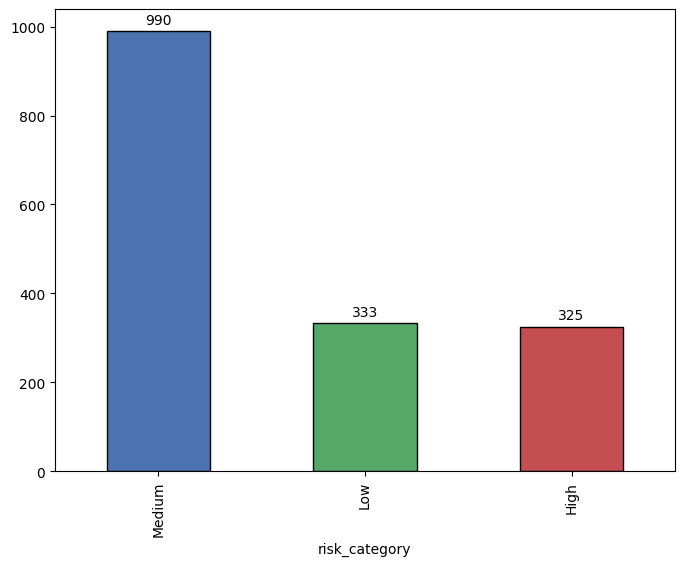

In [42]:
risk_category_cols = df_customer_master['risk_category'].value_counts()
colors = ['#4c72b0', '#55a868', '#c44e52']
plt.figure(figsize=(8,6))
ax = risk_category_cols.plot(kind="bar", color=colors, edgecolor="black")

for c in ax.containers:
    ax.bar_label(c, padding=3)
plt.show()

In [43]:
query = """
SELECT
    c.customer_id as customer_id,
    full_name as name,
    COUNT(ch.claim_id) AS total_claims,
    COALESCE(SUM(ch.claim_amount),0) AS total_claim_amount
FROM customer_master c
LEFT JOIN policy_details p
    ON c.customer_id = p.customer_id
LEFT JOIN claim_history ch
    ON p.policy_id = ch.policy_id
GROUP BY c.customer_id, c.full_name
ORDER BY total_claim_amount DESC, total_claims DESC ;
"""

df_customer_Claims = pd.read_sql_query(query, conn)

display(df_customer_Claims.head())

C:\Users\lokes\AppData\Local\Temp\ipykernel_19308\2774305212.py:16: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df_customer_Claims = pd.read_sql_query(query, conn)


,customer_id,name,total_claims,total_claim_amount
0,CUST10406,Ikshita Grover,7,1845559.47
1,CUST10688,Suhani Kunda,5,1604353.53
2,CUST12260,Aryan Vala,4,1558112.19
3,CUST11033,Maya Munshi,5,1491114.25
4,CUST10833,Dhruv Wable,4,1447913.38


In [44]:
query = """
SELECT 
    c.customer_id AS customer_id,
    c.full_name AS name,
    COUNT(p.policy_id) AS policy_count
FROM customer_master c
LEFT JOIN policy_details p 
    ON c.customer_id = p.customer_id
GROUP BY c.customer_id, c.full_name
ORDER BY policy_count DESC;
"""

df_customer_policy_count = pd.read_sql_query(query, conn)
display(df_customer_policy_count.head())

C:\Users\lokes\AppData\Local\Temp\ipykernel_19308\547590364.py:13: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df_customer_policy_count = pd.read_sql_query(query, conn)


,customer_id,name,policy_count
0,CUST10456,Aadi Kala,6
1,CUST10904,Aarush Nanda,6
2,CUST11316,Rishi Subramaniam,6
3,CUST12248,Lakshmi Iyer,6
4,CUST12446,Chaitanya Borra,6


In [45]:
claims_metrics = df_customer_Claims[['customer_id', 'total_claims', 'total_claim_amount']]

df_customer_master = df_customer_master.merge(claims_metrics, on='customer_id', how='left')

df_customer_master['total_claims'] = df_customer_master['total_claims'].fillna(0).astype(int)
df_customer_master['total_claim_amount'] = df_customer_master['total_claim_amount'].fillna(0.0)


# For customer policy count
policy_metrix = df_customer_policy_count[["customer_id","policy_count"]]
df_customer_master = df_customer_master.merge(policy_metrix, on="customer_id", how="left")
df_customer_master["policy_count"] = df_customer_master["policy_count"].fillna(0).astype(int)

display(df_customer_master.head())

,customer_id,full_name,age,gender,marital_status,occupation,region,smoking_status,pre_existing_illness,risk_score,date_joined,risk_category,total_claims,total_claim_amount,policy_count
0,CUST10000,Yahvi Chander,18,Male,Single,Student,West,No,Yes,0.61,2020-02-02,Medium,1,425110.46,1
1,CUST10001,Gautami Batta,39,Female,Divorced,Salaried,East,Yes,Yes,0.56,2020-04-17,Medium,0,0.00,2
2,CUST10002,Zehaan Randhawa,34,Male,Single,Student,North,Yes,No,0.48,2018-06-27,Medium,1,174124.52,4
3,CUST10003,Aarnav Bhandari,50,Male,Married,Self-employed,South,Yes,No,0.47,2021-12-02,Medium,0,0.00,1
4,CUST10005,Tripti Parekh,20,Female,Single,Student,North,Yes,No,0.55,2022-10-25,Medium,1,109732.19,1


In [46]:
df_customer_master.sort_values(by="total_claims", ascending=False).head()

,customer_id,full_name,age,gender,marital_status,occupation,region,smoking_status,pre_existing_illness,risk_score,date_joined,risk_category,total_claims,total_claim_amount,policy_count
258,CUST10406,Ikshita Grover,41,Male,Single,Self-employed,South,Yes,No,0.52,2018-02-21,Medium,7,1845559.47,5
1035,CUST11579,Zayan Bahl,38,Male,Divorced,Student,North-East,Yes,Yes,0.66,2022-01-30,Medium,6,1349588.87,5
1311,CUST11986,Yauvani Mand,26,Female,Married,Self-employed,Central,Yes,No,0.45,2018-01-05,Medium,5,1250451.61,3
289,CUST10456,Aadi Kala,47,Female,Divorced,Retired,West,No,Yes,0.61,2018-11-28,Medium,5,847037.39,6
827,CUST11277,Krishna Dubey,59,Male,Single,Student,West,Yes,No,0.51,2020-12-22,Medium,5,1240720.41,3


In [47]:
del df_customer_Claims, df_customer_policy_count

In [48]:
df_agent_info['lapse_rate_pct'] = ((df_agent_info['lapsed_policies'] / df_agent_info['total_policies_sold']) * 100).round(2)
df_agent_info['fraud_rate_pct'] = ((df_agent_info['fraud_association'] / df_agent_info['total_policies_sold']) * 100).round(2)
df_agent_info["estimate_premium_book"] = (df_agent_info["total_policies_sold"] * df_agent_info["avg_premium_sold"]).round(2)

display(df_agent_info.head())

,agent_id,region,join_date,total_policies_sold,lapsed_policies,avg_premium_sold,fraud_association,lapse_rate_pct,fraud_rate_pct,estimate_premium_book
0,AGT5000,North,2016-02-15,196,42,37018.35,8,21.43,4.08,7255596.60
1,AGT5001,North,2016-09-05,189,28,48370.36,5,14.81,2.65,9141998.04
2,AGT5002,South,2016-06-26,66,0,10489.65,3,0.00,4.55,692316.90
3,AGT5003,North-East,2016-04-23,250,3,12415.84,6,1.20,2.40,3103960.00
4,AGT5004,South,2022-11-16,263,69,24057.14,4,26.24,1.52,6327027.82


In [49]:
df_agent_info["estimate_premium_book"].agg(["max","min","mean"]).round(2)

max     14790667.12
min       316408.15
mean     4805266.29
Name: estimate_premium_book, dtype: float64

In [50]:
df_agent_info["lapse_rate_pct"].agg(["max","min","mean"]).round(2)

max     29.41
min      0.00
mean    14.82
Name: lapse_rate_pct, dtype: float64

Here I want to segment agents based on their `estimate_premium_book` in `df_agent_info` and ranking them by `sales_tier_estimate`.
For that I am defining lower and upper threshold for sales.

In [51]:
mean_val = df_agent_info['estimate_premium_book'].mean()
std_val = df_agent_info['estimate_premium_book'].std()

t1 = mean_val - (0.5 * std_val)
t2 = mean_val + (0.5 * std_val)

bins = [-np.inf, t1, t2, np.inf]
labels = ['Low', 'Medium', 'High']

df_agent_info['sales_tier_estimate'] = pd.cut(
    df_agent_info['estimate_premium_book'], 
    bins=bins, 
    labels=labels)
print(f'Lower threshold :{t1}\nUpper threshold :{t2}')

Lower threshold :3201184.6483798446
Upper threshold :6409347.93475349


In [52]:
df_agent_info['lapse_rate_category'] = pd.cut(
    df_agent_info['lapse_rate_pct'], 
    bins=[-np.inf, 10, 20, np.inf], 
    labels=['Low', 'Medium', 'High'])
df_agent_info.head()

,agent_id,region,join_date,total_policies_sold,lapsed_policies,avg_premium_sold,fraud_association,lapse_rate_pct,fraud_rate_pct,estimate_premium_book,sales_tier_estimate,lapse_rate_category
0,AGT5000,North,2016-02-15,196,42,37018.35,8,21.43,4.08,7255596.60,High,High
1,AGT5001,North,2016-09-05,189,28,48370.36,5,14.81,2.65,9141998.04,High,Medium
2,AGT5002,South,2016-06-26,66,0,10489.65,3,0.00,4.55,692316.90,Low,Low
3,AGT5003,North-East,2016-04-23,250,3,12415.84,6,1.20,2.40,3103960.00,Low,Low
4,AGT5004,South,2022-11-16,263,69,24057.14,4,26.24,1.52,6327027.82,Medium,High


##### Policy_Details Table

In [53]:
df_policy_details.head()

,policy_id,customer_id,product_type,coverage_amount,annual_premium,policy_start_date,policy_end_date,agent_id,status
0,POL50001,CUST10833,Property,169869.71,27193.94,2021-07-25,2022-10-25,AGT5238,Active
1,POL50002,CUST11786,Health,546514.84,19603.44,2022-09-19,2024-04-29,AGT5008,Cancelled
2,POL50003,CUST10501,Property,944249.15,36274.58,2022-12-08,2025-04-23,AGT5118,Cancelled
3,POL50004,CUST10349,Property,209475.32,23091.58,2024-04-09,2024-07-20,AGT5090,Active
4,POL50005,CUST12296,Term,887938.35,10458.22,2022-10-08,2024-12-12,AGT5050,Lapsed


In [54]:
df_policy_details["policy_duration_days"] = (df_policy_details["policy_end_date"]-df_policy_details["policy_start_date"]
                                            ).dt.days

df_policy_details["premium_rate"] = ((df_policy_details["annual_premium"]/df_policy_details["coverage_amount"]
                                                  )*100).round(2)
display(df_policy_details.head())

,policy_id,customer_id,product_type,coverage_amount,annual_premium,policy_start_date,policy_end_date,agent_id,status,policy_duration_days,premium_rate
0,POL50001,CUST10833,Property,169869.71,27193.94,2021-07-25,2022-10-25,AGT5238,Active,457,16.01
1,POL50002,CUST11786,Health,546514.84,19603.44,2022-09-19,2024-04-29,AGT5008,Cancelled,588,3.59
2,POL50003,CUST10501,Property,944249.15,36274.58,2022-12-08,2025-04-23,AGT5118,Cancelled,867,3.84
3,POL50004,CUST10349,Property,209475.32,23091.58,2024-04-09,2024-07-20,AGT5090,Active,102,11.02
4,POL50005,CUST12296,Term,887938.35,10458.22,2022-10-08,2024-12-12,AGT5050,Lapsed,796,1.18


In [55]:
df_policy_details["active_flag"] = (df_policy_details["status"]=="Active").astype(int)
df_policy_details.head()

,policy_id,customer_id,product_type,coverage_amount,annual_premium,policy_start_date,policy_end_date,agent_id,status,policy_duration_days,premium_rate,active_flag
0,POL50001,CUST10833,Property,169869.71,27193.94,2021-07-25,2022-10-25,AGT5238,Active,457,16.01,1
1,POL50002,CUST11786,Health,546514.84,19603.44,2022-09-19,2024-04-29,AGT5008,Cancelled,588,3.59,0
2,POL50003,CUST10501,Property,944249.15,36274.58,2022-12-08,2025-04-23,AGT5118,Cancelled,867,3.84,0
3,POL50004,CUST10349,Property,209475.32,23091.58,2024-04-09,2024-07-20,AGT5090,Active,102,11.02,1
4,POL50005,CUST12296,Term,887938.35,10458.22,2022-10-08,2024-12-12,AGT5050,Lapsed,796,1.18,0


In [56]:
df_policy_details = df_policy_details[
    ['policy_id',
     'customer_id',
     'product_type',
     'coverage_amount',
     'annual_premium',
     'premium_rate',
     'policy_start_date',
     'policy_end_date',
     'policy_duration_days',
     'agent_id',
     'status',
     'active_flag',]
]
df_policy_details.head()

,policy_id,customer_id,product_type,coverage_amount,annual_premium,premium_rate,policy_start_date,policy_end_date,policy_duration_days,agent_id,status,active_flag
0,POL50001,CUST10833,Property,169869.71,27193.94,16.01,2021-07-25,2022-10-25,457,AGT5238,Active,1
1,POL50002,CUST11786,Health,546514.84,19603.44,3.59,2022-09-19,2024-04-29,588,AGT5008,Cancelled,0
2,POL50003,CUST10501,Property,944249.15,36274.58,3.84,2022-12-08,2025-04-23,867,AGT5118,Cancelled,0
3,POL50004,CUST10349,Property,209475.32,23091.58,11.02,2024-04-09,2024-07-20,102,AGT5090,Active,1
4,POL50005,CUST12296,Term,887938.35,10458.22,1.18,2022-10-08,2024-12-12,796,AGT5050,Lapsed,0


##### Claim_History Table

In [57]:
df_claim_history.head()

,claim_id,policy_id,claim_date,claim_amount,claim_status,claim_type,fraud_flag,days_to_process
0,CLM70003,POL51902,2022-10-10,379127.79,Pending,Theft,No,40
1,CLM70004,POL50001,2021-12-06,431984.06,Approved,Hospital,No,56
2,CLM70005,POL53707,2024-07-17,206765.82,Rejected,Death,No,39
3,CLM70006,POL53642,2024-06-12,225358.05,Approved,Accident,Yes,22
4,CLM70007,POL51744,2024-06-13,340208.27,Rejected,Theft,No,31


In [58]:
df_claim_history.info()

<class 'pandas.DataFrame'>
RangeIndex: 1406 entries, 0 to 1405
Data columns (total 8 columns):
 #   Column           Non-Null Count  Dtype        
---  ------           --------------  -----        
 0   claim_id         1406 non-null   str          
 1   policy_id        1406 non-null   str          
 2   claim_date       1406 non-null   datetime64[s]
 3   claim_amount     1406 non-null   float64      
 4   claim_status     1406 non-null   str          
 5   claim_type       1406 non-null   str          
 6   fraud_flag       1406 non-null   str          
 7   days_to_process  1406 non-null   int64        
dtypes: datetime64[s](1), float64(1), int64(1), str(5)
memory usage: 88.0 KB


In [59]:
df_claim_history["month"] = df_claim_history["claim_date"].dt.month
df_claim_history["year"] = df_claim_history["claim_date"].dt.year

df_claim_history.head()

,claim_id,policy_id,claim_date,claim_amount,claim_status,claim_type,fraud_flag,days_to_process,month,year
0,CLM70003,POL51902,2022-10-10,379127.79,Pending,Theft,No,40,10,2022
1,CLM70004,POL50001,2021-12-06,431984.06,Approved,Hospital,No,56,12,2021
2,CLM70005,POL53707,2024-07-17,206765.82,Rejected,Death,No,39,7,2024
3,CLM70006,POL53642,2024-06-12,225358.05,Approved,Accident,Yes,22,6,2024
4,CLM70007,POL51744,2024-06-13,340208.27,Rejected,Theft,No,31,6,2024


In [60]:
df_claim_history['payout_amount'] = np.where(df_claim_history['claim_status'] == 'Approved',df_claim_history['claim_amount'],0.0,)
df_claim_history.head()

,claim_id,policy_id,claim_date,claim_amount,claim_status,claim_type,fraud_flag,days_to_process,month,year,payout_amount
0,CLM70003,POL51902,2022-10-10,379127.79,Pending,Theft,No,40,10,2022,0.00
1,CLM70004,POL50001,2021-12-06,431984.06,Approved,Hospital,No,56,12,2021,431984.06
2,CLM70005,POL53707,2024-07-17,206765.82,Rejected,Death,No,39,7,2024,0.00
3,CLM70006,POL53642,2024-06-12,225358.05,Approved,Accident,Yes,22,6,2024,225358.05
4,CLM70007,POL51744,2024-06-13,340208.27,Rejected,Theft,No,31,6,2024,0.00


In [61]:
df_claim_history['claim_value'] = pd.cut(df_claim_history['claim_amount'],
                                                bins=[-np.inf,150000,300000,np.inf],
                                                labels=['Low', 'Medium', 'High'])

display(df_claim_history.groupby('claim_value')['claim_amount'].agg(['min', 'max', 'count']))

,min,max,count
claim_value,,,
Low,10149.32,149582.53,409
Medium,150690.37,299995.48,436
High,300508.35,499431.20,561


In [62]:
df_claim_history['approved_flag'] = (df_claim_history['claim_status'] == 'Approved').astype(int)
df_claim_history['rejected_flag'] = (df_claim_history['claim_status'] == 'Rejected').astype(int)
df_claim_history['fraud_flag_numeric'] = (df_claim_history['fraud_flag'] == 'Yes').astype(int)
df_claim_history.head()

,claim_id,policy_id,claim_date,claim_amount,claim_status,claim_type,fraud_flag,days_to_process,month,year,payout_amount,claim_value,approved_flag,rejected_flag,fraud_flag_numeric
0,CLM70003,POL51902,2022-10-10,379127.79,Pending,Theft,No,40,10,2022,0.00,High,0,0,0
1,CLM70004,POL50001,2021-12-06,431984.06,Approved,Hospital,No,56,12,2021,431984.06,High,1,0,0
2,CLM70005,POL53707,2024-07-17,206765.82,Rejected,Death,No,39,7,2024,0.00,Medium,0,1,0
3,CLM70006,POL53642,2024-06-12,225358.05,Approved,Accident,Yes,22,6,2024,225358.05,Medium,1,0,1
4,CLM70007,POL51744,2024-06-13,340208.27,Rejected,Theft,No,31,6,2024,0.00,High,0,1,0


In [63]:
df_claim_history['processing_speed'] = pd.cut(df_claim_history['days_to_process'],
                                              bins=[-np.inf,15,30,45,np.inf],
                                              labels=["Fast","Moderate","Slow","Very Slow"])

display(df_claim_history.groupby('processing_speed')['days_to_process'].agg(['min', 'max', 'count']))
df_claim_history.head()

,min,max,count
processing_speed,,,
Fast,2,15,320
Moderate,16,30,346
Slow,31,45,398
Very Slow,46,59,342


,claim_id,policy_id,claim_date,claim_amount,claim_status,claim_type,fraud_flag,days_to_process,month,year,payout_amount,claim_value,approved_flag,rejected_flag,fraud_flag_numeric,processing_speed
0,CLM70003,POL51902,2022-10-10,379127.79,Pending,Theft,No,40,10,2022,0.00,High,0,0,0,Slow
1,CLM70004,POL50001,2021-12-06,431984.06,Approved,Hospital,No,56,12,2021,431984.06,High,1,0,0,Very Slow
2,CLM70005,POL53707,2024-07-17,206765.82,Rejected,Death,No,39,7,2024,0.00,Medium,0,1,0,Slow
3,CLM70006,POL53642,2024-06-12,225358.05,Approved,Accident,Yes,22,6,2024,225358.05,Medium,1,0,1,Moderate
4,CLM70007,POL51744,2024-06-13,340208.27,Rejected,Theft,No,31,6,2024,0.00,High,0,1,0,Slow


In [64]:
list(df_claim_history.columns)

['claim_id',
 'policy_id',
 'claim_date',
 'claim_amount',
 'claim_status',
 'claim_type',
 'fraud_flag',
 'days_to_process',
 'month',
 'year',
 'payout_amount',
 'claim_value',
 'approved_flag',
 'rejected_flag',
 'fraud_flag_numeric',
 'processing_speed']

In [65]:
df_claim_history = df_claim_history[
        ['claim_id',
         'policy_id',
         'claim_date',
         'month',
         'year',
         'claim_type',
         'claim_amount',
         'claim_status',
         'payout_amount',
         'claim_value',
         'days_to_process',
         'processing_speed',
         'fraud_flag',
         'approved_flag',
         'rejected_flag',
         'fraud_flag_numeric',]]
df_claim_history.head()

,claim_id,policy_id,claim_date,month,year,claim_type,claim_amount,claim_status,payout_amount,claim_value,days_to_process,processing_speed,fraud_flag,approved_flag,rejected_flag,fraud_flag_numeric
0,CLM70003,POL51902,2022-10-10,10,2022,Theft,379127.79,Pending,0.00,High,40,Slow,No,0,0,0
1,CLM70004,POL50001,2021-12-06,12,2021,Hospital,431984.06,Approved,431984.06,High,56,Very Slow,No,1,0,0
2,CLM70005,POL53707,2024-07-17,7,2024,Death,206765.82,Rejected,0.00,Medium,39,Slow,No,0,1,0
3,CLM70006,POL53642,2024-06-12,6,2024,Accident,225358.05,Approved,225358.05,Medium,22,Moderate,Yes,1,0,1
4,CLM70007,POL51744,2024-06-13,6,2024,Theft,340208.27,Rejected,0.00,High,31,Slow,No,0,1,0


In [66]:
score_map = {
    1: 'Dissatisfied',
    2: 'Dissatisfied',
    3: 'Neutral',
    4: 'Satisfied',
    5: 'Satisfied',}

df_customer_feedback['satisfaction_category'] = (df_customer_feedback['satisfaction_score'].map(score_map))
df_customer_feedback.head()

,feedback_id,customer_id,date_submitted,feedback_text,satisfaction_score,contacted_agent,referred_claim,satisfaction_category
0,FDB90000,CUST11838,2020-08-07,I'm not happy with the premium charged.,3,Yes,Yes,Neutral
1,FDB90001,CUST12252,2021-01-13,I'm not happy with the premium charged.,1,No,Yes,Dissatisfied
2,FDB90002,CUST10495,2022-02-16,Smooth experience with no issues.,5,No,Yes,Satisfied
3,FDB90003,CUST11182,2021-02-16,Claim process could be faster.,2,No,Yes,Dissatisfied
4,FDB90004,CUST11047,2021-04-09,The agent was helpful and explained everything.,5,No,No,Satisfied


In [67]:
df_customer_feedback["satisfaction_flag"] =(df_customer_feedback["satisfaction_score"]>=4).astype(int)
df_customer_feedback["claim_related_feedback_flag"] = (df_customer_feedback["referred_claim"]=="Yes").astype(int)
df_customer_feedback["identified_feedback_flag"] = (df_customer_feedback["customer_id"].notna().astype(int))

df_customer_feedback["month"] = df_customer_feedback["date_submitted"].dt.month
df_customer_feedback["year"] = df_customer_feedback["date_submitted"].dt.year

df_customer_feedback['customer_id_display'] = (df_customer_feedback['customer_id'].fillna('Anonymous'))
df_customer_feedback

df_customer_feedback.head()

,feedback_id,customer_id,date_submitted,feedback_text,satisfaction_score,contacted_agent,referred_claim,satisfaction_category,satisfaction_flag,claim_related_feedback_flag,identified_feedback_flag,month,year,customer_id_display
0,FDB90000,CUST11838,2020-08-07,I'm not happy with the premium charged.,3,Yes,Yes,Neutral,0,1,1,8,2020,CUST11838
1,FDB90001,CUST12252,2021-01-13,I'm not happy with the premium charged.,1,No,Yes,Dissatisfied,0,1,1,1,2021,CUST12252
2,FDB90002,CUST10495,2022-02-16,Smooth experience with no issues.,5,No,Yes,Satisfied,1,1,1,2,2022,CUST10495
3,FDB90003,CUST11182,2021-02-16,Claim process could be faster.,2,No,Yes,Dissatisfied,0,1,1,2,2021,CUST11182
4,FDB90004,CUST11047,2021-04-09,The agent was helpful and explained everything.,5,No,No,Satisfied,1,0,1,4,2021,CUST11047


In [68]:
df_customer_feedback = df_customer_feedback[
    ['feedback_id',
     'customer_id',
     'customer_id_display',
     'date_submitted',
     'month',
     'year',
     'feedback_text',
     'satisfaction_score',
     'satisfaction_category',
     'satisfaction_flag',
     'contacted_agent',
     'referred_claim',
     'claim_related_feedback_flag',
     'identified_feedback_flag',]
]
df_customer_feedback.head()

,feedback_id,customer_id,customer_id_display,date_submitted,month,year,feedback_text,satisfaction_score,satisfaction_category,satisfaction_flag,contacted_agent,referred_claim,claim_related_feedback_flag,identified_feedback_flag
0,FDB90000,CUST11838,CUST11838,2020-08-07,8,2020,I'm not happy with the premium charged.,3,Neutral,0,Yes,Yes,1,1
1,FDB90001,CUST12252,CUST12252,2021-01-13,1,2021,I'm not happy with the premium charged.,1,Dissatisfied,0,No,Yes,1,1
2,FDB90002,CUST10495,CUST10495,2022-02-16,2,2022,Smooth experience with no issues.,5,Satisfied,1,No,Yes,1,1
3,FDB90003,CUST11182,CUST11182,2021-02-16,2,2021,Claim process could be faster.,2,Dissatisfied,0,No,Yes,1,1
4,FDB90004,CUST11047,CUST11047,2021-04-09,4,2021,The agent was helpful and explained everything.,5,Satisfied,1,No,No,0,1


#### Monthly Claim_Amount vs Paid_Amount

In [69]:
monthly_claims_df = (
    df_claim_history
    .groupby(["year","month"],as_index=False)
    .agg(total_claim_amount=("claim_amount","sum"),
         total_paid_amount=("payout_amount","sum"))
    .sort_values(by=["year","month"]).reset_index(drop=True)
)

monthly_claims_df['period'] = pd.to_datetime(
    dict(year=monthly_claims_df['year'].astype(int),
         month=monthly_claims_df['month'].astype(int),
         day=1)
)

monthly_claims_df

,year,month,total_claim_amount,total_paid_amount,period
0,2020,8,202606.89,0.00,2020-08-01
1,2020,9,256785.91,256785.91,2020-09-01
2,2020,10,902470.07,902470.07,2020-10-01
3,2020,11,2301272.37,1447261.69,2020-11-01
4,2020,12,1019331.72,1019331.72,2020-12-01
5,2021,1,1414060.31,493489.37,2021-01-01
6,2021,2,727556.90,419962.05,2021-02-01
7,2021,3,1675122.76,353965.39,2021-03-01
8,2021,4,121358.55,121358.55,2021-04-01
9,2021,5,1302311.66,816693.27,2021-05-01


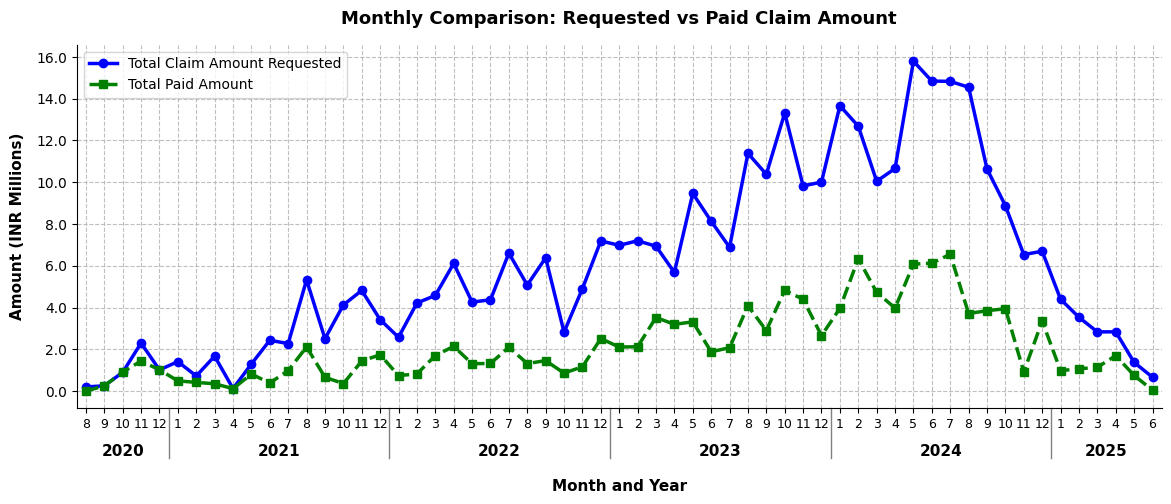

In [70]:
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import seaborn as sns

plot_df = monthly_claims_df.copy()
plot_df['requested_m'] = plot_df['total_claim_amount'] / 1_000_000
plot_df['paid_m'] = plot_df['total_paid_amount'] / 1_000_000

month_index = plot_df['year'].astype(int) * 12 + plot_df['month'].astype(int)
plot_df['pos'] = month_index - month_index.min()
plot_df['month_label'] = plot_df['month'].astype(int).astype(str)

fig, ax = plt.subplots(figsize=(14, 5.5))

ax.plot(plot_df['pos'], plot_df['requested_m'],
        marker='o', linewidth=2.5, color='blue',
        label='Total Claim Amount Requested')

ax.plot(plot_df['pos'], plot_df['paid_m'],
        marker='s', linewidth=2.5, color='green', linestyle='--',
        label='Total Paid Amount')

ax.set_xticks(plot_df['pos'])
ax.set_xticklabels(plot_df['month_label'], fontsize=9)
ax.set_xlim(plot_df['pos'].min() - 0.5, plot_df['pos'].max() + 0.5)

year_transform = ax.get_xaxis_transform()
years = list(plot_df.groupby('year'))

for i, (year, group) in enumerate(years):
    center = (group['pos'].min() + group['pos'].max()) / 2
    ax.text(center, -0.10, str(int(year)), transform=year_transform,
            ha='center', va='top', fontsize=11, fontweight='bold')

    if i > 0:
        boundary = group['pos'].min() - 0.5
        ax.plot([boundary, boundary], [0, -0.14], transform=year_transform,
                color='gray', linewidth=1, clip_on=False)

ax.set_title('Monthly Comparison: Requested vs Paid Claim Amount',
             fontsize=13, fontweight='bold', pad=15)
ax.set_xlabel('Month and Year', fontsize=11, fontweight='bold', labelpad=35)
ax.set_ylabel('Amount (INR Millions)', fontsize=11, fontweight='bold', labelpad=8)

ax.yaxis.set_major_formatter(ticker.StrMethodFormatter('{x:,.1f}'))
ax.grid(True, linestyle='--', alpha=0.8)
ax.legend(facecolor='white', loc='upper left')

sns.despine()
plt.subplots_adjust(bottom=0.22)
plt.show()

In [71]:
query = """
SELECT
    c.region,
    COUNT(ch.claim_id) AS total_claims,
    ROUND(SUM(ch.claim_amount),2) AS total_claim_amount,
    ROUND(AVG(ch.claim_amount), 2) AS avg_claim_amount
FROM customer_master c
JOIN policy_details p
    ON c.customer_id = p.customer_id
JOIN claim_history ch
    ON p.policy_id = ch.policy_id
GROUP BY c.region
ORDER BY total_claims DESC;
"""

df_region_claim_metrix = pd.read_sql_query(query, conn)

display(df_region_claim_metrix)

C:\Users\lokes\AppData\Local\Temp\ipykernel_19308\3116397181.py:16: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df_region_claim_metrix = pd.read_sql_query(query, conn)


,region,total_claims,total_claim_amount,avg_claim_amount
0,West,261,64814090.46,248329.85
1,Central,254,64852645.21,255325.37
2,East,237,61725106.45,260443.49
3,South,232,60948673.22,262709.80
4,North,230,55596617.57,241724.42
5,North-East,192,47685864.84,248363.88


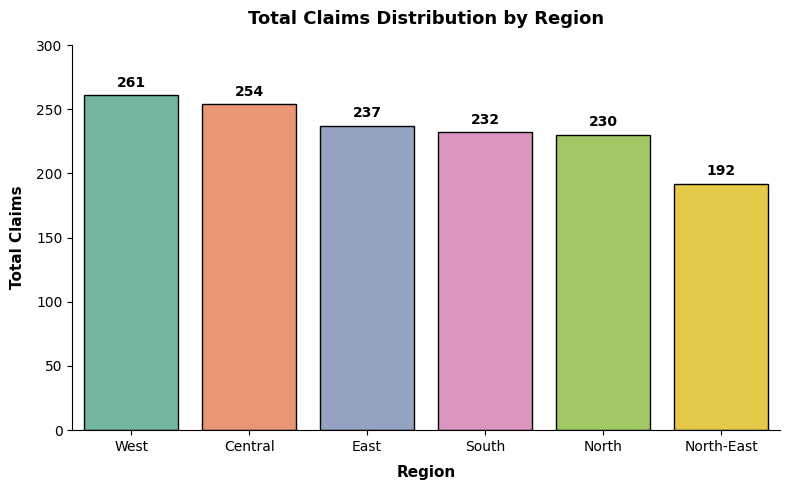

In [72]:
plt.figure(figsize=(8, 5))
ax = sns.barplot(
    data=df_region_claim_metrix,
    x='region',
    y='total_claims',
    hue="region",
    dodge=False,
    palette='Set2',
    edgecolor='black',)

ax.legend_ = None
for c in ax.containers:
    ax.bar_label(c, padding=4, fontweight='bold', fontsize=10)

plt.title('Total Claims Distribution by Region', fontsize=13, fontweight='bold', pad=15)
plt.xlabel('Region', fontsize=11, fontweight='bold', labelpad=8)
plt.ylabel('Total Claims', fontsize=11, fontweight='bold', labelpad=8)
plt.ylim(0, df_region_claim_metrix['total_claims'].max() * 1.15)

sns.despine()
plt.tight_layout()
plt.show()

In [73]:
df_claim_history

,claim_id,policy_id,claim_date,month,year,claim_type,claim_amount,claim_status,payout_amount,claim_value,days_to_process,processing_speed,fraud_flag,approved_flag,rejected_flag,fraud_flag_numeric
0,CLM70003,POL51902,2022-10-10,10,2022,Theft,379127.79,Pending,0.00,High,40,Slow,No,0,0,0
1,CLM70004,POL50001,2021-12-06,12,2021,Hospital,431984.06,Approved,431984.06,High,56,Very Slow,No,1,0,0
2,CLM70005,POL53707,2024-07-17,7,2024,Death,206765.82,Rejected,0.00,Medium,39,Slow,No,0,1,0
3,CLM70006,POL53642,2024-06-12,6,2024,Accident,225358.05,Approved,225358.05,Medium,22,Moderate,Yes,1,0,1
4,CLM70007,POL51744,2024-06-13,6,2024,Theft,340208.27,Rejected,0.00,High,31,Slow,No,0,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1401,CLM71991,POL50232,2024-09-22,9,2024,Other,399400.01,Rejected,0.00,High,50,Very Slow,No,0,1,0
1402,CLM71994,POL51511,2024-01-29,1,2024,Hospital,109732.19,Rejected,0.00,Low,41,Slow,Yes,0,1,1
1403,CLM71997,POL51754,2024-02-13,2,2024,Accident,438345.46,Approved,438345.46,High,46,Very Slow,No,1,0,0
1404,CLM71998,POL52975,2022-03-30,3,2022,Other,373093.50,Rejected,0.00,High,23,Moderate,No,0,1,0


In [74]:
df_claim_level_master = df_claim_history.merge(
    df_policy_details[['policy_id', 'customer_id', 'product_type']],
    on='policy_id',
    how='left',
).merge(df_customer_master[['customer_id', 'region']], on='customer_id', how='left')

df_pivot_paid = (pd.pivot_table(
        df_claim_level_master,
        index='region',
        columns='product_type',
        values='payout_amount',
        aggfunc='sum',)/ 1e6) 

df_pivot_claim = (pd.pivot_table(
        df_claim_level_master,
        index='region',
        columns='product_type',
        values='claim_amount',
        aggfunc='sum',)/ 1e6) 

display(df_pivot_paid.head())
display(df_pivot_claim.head())

product_type,Health,Property,Term,Vehicle,Whole
region,,,,,
Central,5.593704,4.515354,3.893107,4.971437,6.302111
East,5.767635,2.902661,3.765992,7.029679,3.592698
North,4.076930,2.170880,3.948905,4.227861,5.945551
North-East,4.152287,1.551583,4.145054,2.993099,1.705413
South,4.099340,5.307343,4.685610,5.234780,4.895485


product_type,Health,Property,Term,Vehicle,Whole
region,,,,,
Central,14.879226,14.686443,8.837275,12.724088,13.725614
East,14.419970,12.026289,10.332865,14.799910,10.146071
North,12.033386,7.574122,12.215615,9.694264,14.079230
North-East,11.390260,10.482598,8.601644,10.711485,6.499878
South,11.133416,15.972291,13.644446,9.261810,10.936710


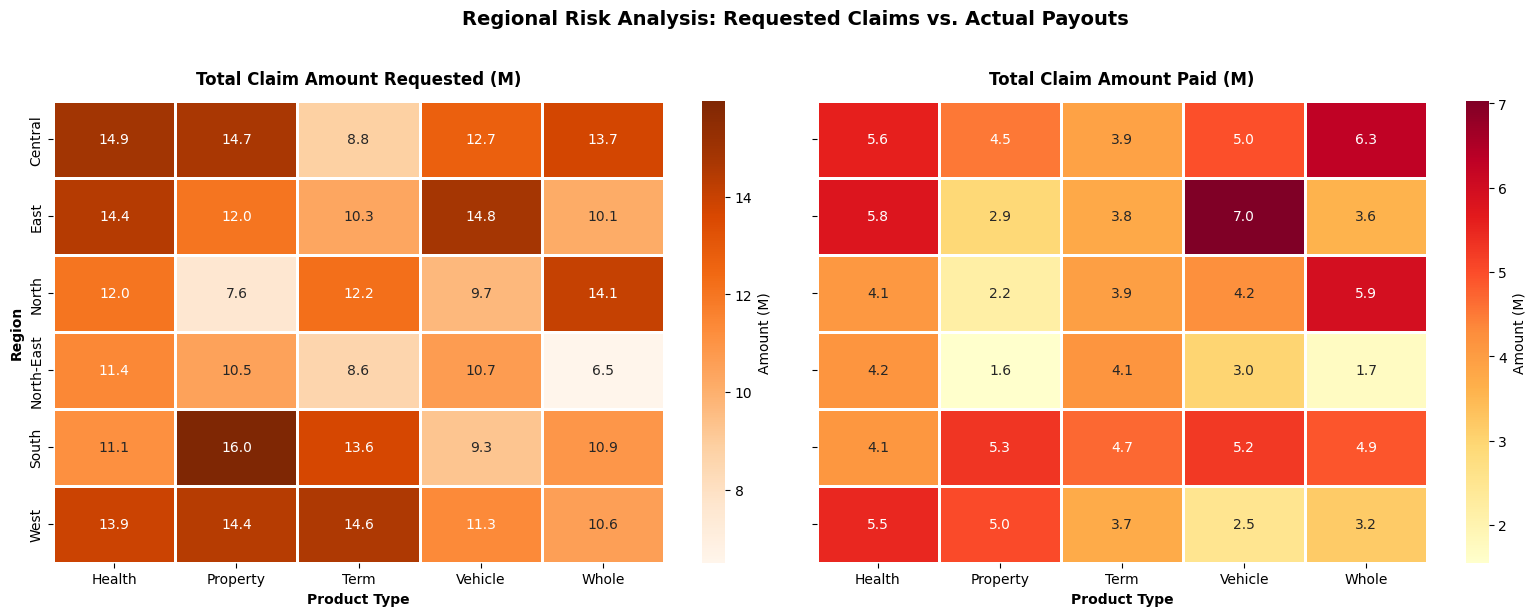

In [75]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6), sharey=True)

sns.heatmap(
    df_pivot_claim,
    annot=True,
    fmt='.1f',
    cmap='Oranges',
    linewidths=0.8,
    linecolor='white',
    cbar_kws={'label': 'Amount (M)'},
    ax=axes[0],
)

axes[0].set_title('Total Claim Amount Requested (M)', fontsize=12, fontweight='bold', pad=12)
axes[0].set_xlabel('Product Type', fontsize=10, fontweight='bold')
axes[0].set_ylabel('Region', fontsize=10, fontweight='bold')

#-------------------------------------------------------------------
sns.heatmap(
    df_pivot_paid,
    annot=True,
    fmt='.1f',
    cmap='YlOrRd',
    linewidths=0.8,
    linecolor='white',
    cbar_kws={'label': 'Amount (M)'},
    ax=axes[1],
)
axes[1].set_title('Total Claim Amount Paid (M)', fontsize=12, fontweight='bold', pad=12)
axes[1].set_xlabel('Product Type', fontsize=10, fontweight='bold')
axes[1].set_ylabel('')

plt.suptitle(
    'Regional Risk Analysis: Requested Claims vs. Actual Payouts',
    fontsize=14,
    fontweight='bold',
    y=1.02,
)
plt.tight_layout()
plt.show()

In [76]:
product_policy_data = df_policy_details.merge(df_claim_history,on="policy_id", how="left").groupby("product_type").agg(total_policies=("policy_id","nunique"),
                                                                                 total_claimed_amount=("claim_amount","sum"),
                                                                                 total_paid_amount=("payout_amount","sum")
                                                                                 ).reset_index()
product_policy_data

,product_type,total_policies,total_claimed_amount,total_paid_amount
0,Health,585,77777956.58,29158037.10
1,Property,567,75128333.72,21473940.11
2,Term,545,68210871.45,24180600.05
3,Vehicle,591,68532832.91,26971276.38
4,Whole,540,65973003.09,25604831.07


In [77]:
product_policy_data['payout_ratio_vs_claimed'] = ((product_policy_data['total_paid_amount'] / product_policy_data['total_claimed_amount']) * 100).round(2)
product_policy_data['avg_claim_per_policy'] = (product_policy_data['total_claimed_amount'] / product_policy_data['total_policies']).round(2)
product_policy_data['avg_payout_per_policy'] = (product_policy_data['total_paid_amount'] / product_policy_data['total_policies']).round(2)

product_policy_data

,product_type,total_policies,total_claimed_amount,total_paid_amount,payout_ratio_vs_claimed,avg_claim_per_policy,avg_payout_per_policy
0,Health,585,77777956.58,29158037.10,37.49,132953.77,49842.80
1,Property,567,75128333.72,21473940.11,28.58,132501.47,37872.91
2,Term,545,68210871.45,24180600.05,35.45,125157.56,44368.07
3,Vehicle,591,68532832.91,26971276.38,39.36,115960.80,45636.68
4,Whole,540,65973003.09,25604831.07,38.81,122172.23,47416.35


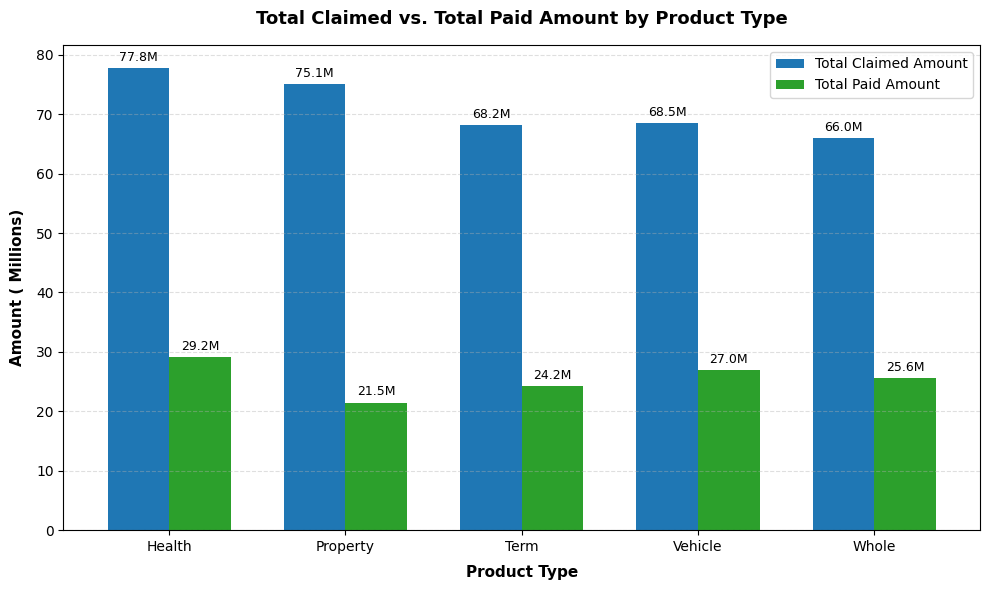

In [78]:
plot_df = (product_policy_data.set_index('product_type')[['total_claimed_amount', 'total_paid_amount']]/ 1e6)
plot_df.columns = ['Total Claimed Amount', 'Total Paid Amount']

ax = plot_df.plot(kind='bar', figsize=(10, 6), color=['#1f77b4', '#2ca02c'], width=0.7)


plt.title('Total Claimed vs. Total Paid Amount by Product Type',fontsize=13,fontweight='bold',pad=15)
plt.xlabel('Product Type', fontsize=11, fontweight='bold', labelpad=8)
plt.ylabel('Amount ( Millions)', fontsize=11, fontweight='bold', labelpad=8)
plt.xticks(rotation=0)
plt.grid(axis='y', linestyle='--', alpha=0.4)
plt.legend(frameon=True, facecolor='white')

for container in ax.containers:
    ax.bar_label(container, fmt='%.1fM', padding=3, fontsize=9)

plt.tight_layout()
plt.show()

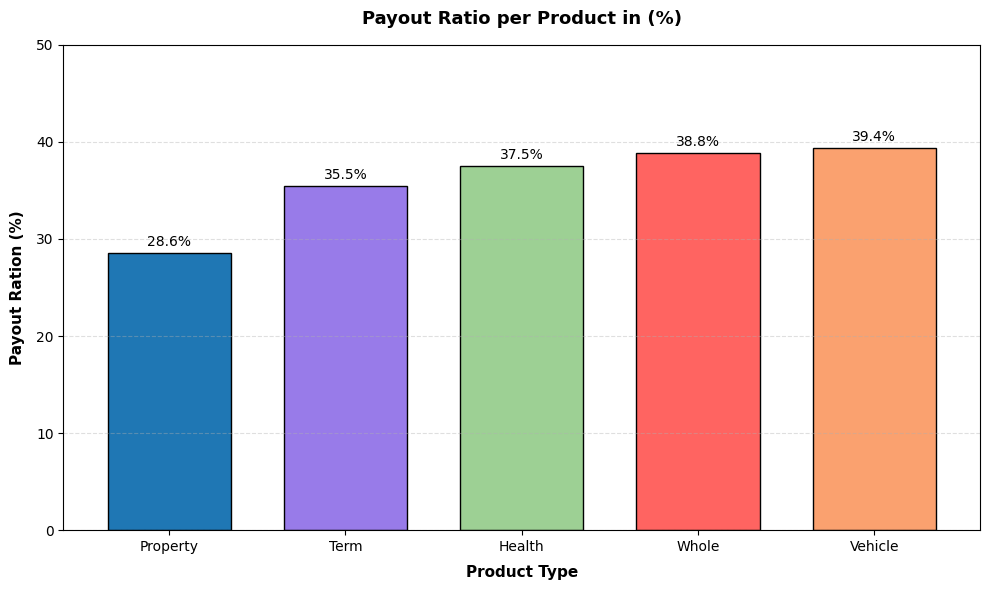

In [79]:
plot_df = (product_policy_data.set_index('product_type')["payout_ratio_vs_claimed"].sort_values(ascending=True))

ax = plot_df.plot(kind='bar', figsize=(10, 6), color=["#1f77b4","#987BE9","#9DD094","#FF6461","#FAA16F"], width=0.7, edgecolor="black")

plt.title('Payout Ratio per Product in (%)',fontsize=13,fontweight='bold',pad=15)
plt.xlabel('Product Type', fontsize=11, fontweight='bold', labelpad=8)
plt.ylabel('Payout Ration (%)', fontsize=11, fontweight='bold', labelpad=8)
plt.xticks(rotation=0)
plt.ylim(0,50)
plt.grid(axis='y', linestyle='--', alpha=0.4)

for container in ax.containers:
    ax.bar_label(container, fmt='%.1f%%', padding=3, fontsize=10)

plt.tight_layout()
plt.show()

In [80]:
df_claimed_only = df_claim_history.merge(df_policy_details[["policy_id","customer_id","product_type"]],
                                         on="policy_id",how="left").merge(df_customer_master[["customer_id","region"]]
                                                ,on="customer_id",how="left")
df_claimed_only.head()

,claim_id,policy_id,claim_date,month,year,claim_type,claim_amount,claim_status,payout_amount,claim_value,days_to_process,processing_speed,fraud_flag,approved_flag,rejected_flag,fraud_flag_numeric,customer_id,product_type,region
0,CLM70003,POL51902,2022-10-10,10,2022,Theft,379127.79,Pending,0.00,High,40,Slow,No,0,0,0,CUST11700,Term,East
1,CLM70004,POL50001,2021-12-06,12,2021,Hospital,431984.06,Approved,431984.06,High,56,Very Slow,No,1,0,0,CUST10833,Property,Central
2,CLM70005,POL53707,2024-07-17,7,2024,Death,206765.82,Rejected,0.00,Medium,39,Slow,No,0,1,0,CUST11843,Property,North
3,CLM70006,POL53642,2024-06-12,6,2024,Accident,225358.05,Approved,225358.05,Medium,22,Moderate,Yes,1,0,1,CUST11314,Vehicle,East
4,CLM70007,POL51744,2024-06-13,6,2024,Theft,340208.27,Rejected,0.00,High,31,Slow,No,0,1,0,CUST10557,Whole,South


C:\Users\lokes\AppData\Local\Temp\ipykernel_19308\1207848650.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
C:\Users\lokes\AppData\Local\Temp\ipykernel_19308\1207848650.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


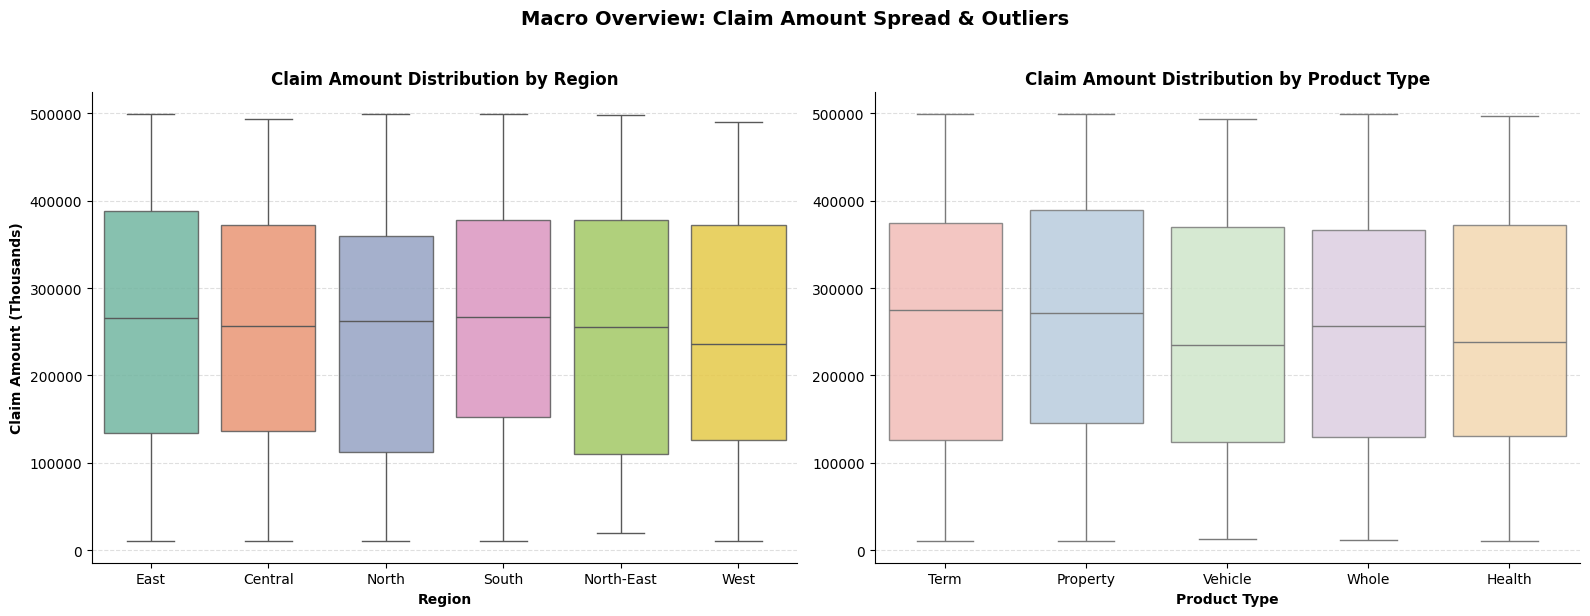

In [81]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.boxplot(
    data=df_claimed_only,
    x='region',
    y='claim_amount',
    palette='Set2',
    ax=axes[0],
    boxprops=dict(alpha=0.85))

axes[0].set_title('Claim Amount Distribution by Region', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Region', fontweight='bold')
axes[0].set_ylabel('Claim Amount (Thousands)', fontweight='bold')
axes[0].grid(axis='y', linestyle='--', alpha=0.4)

# Subplot 2: Product-level distribution
sns.boxplot(
    data=df_claimed_only,
    x='product_type',
    y='claim_amount',
    palette='Pastel1',
    ax=axes[1],
    boxprops=dict(alpha=0.85))

axes[1].set_title('Claim Amount Distribution by Product Type', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Product Type', fontweight='bold')
axes[1].set_ylabel('')
axes[1].grid(axis='y', linestyle='--', alpha=0.4)

plt.suptitle('Macro Overview: Claim Amount Spread & Outliers',fontsize=14,fontweight='bold',y=1.02,)
sns.despine()
plt.tight_layout()
plt.show()

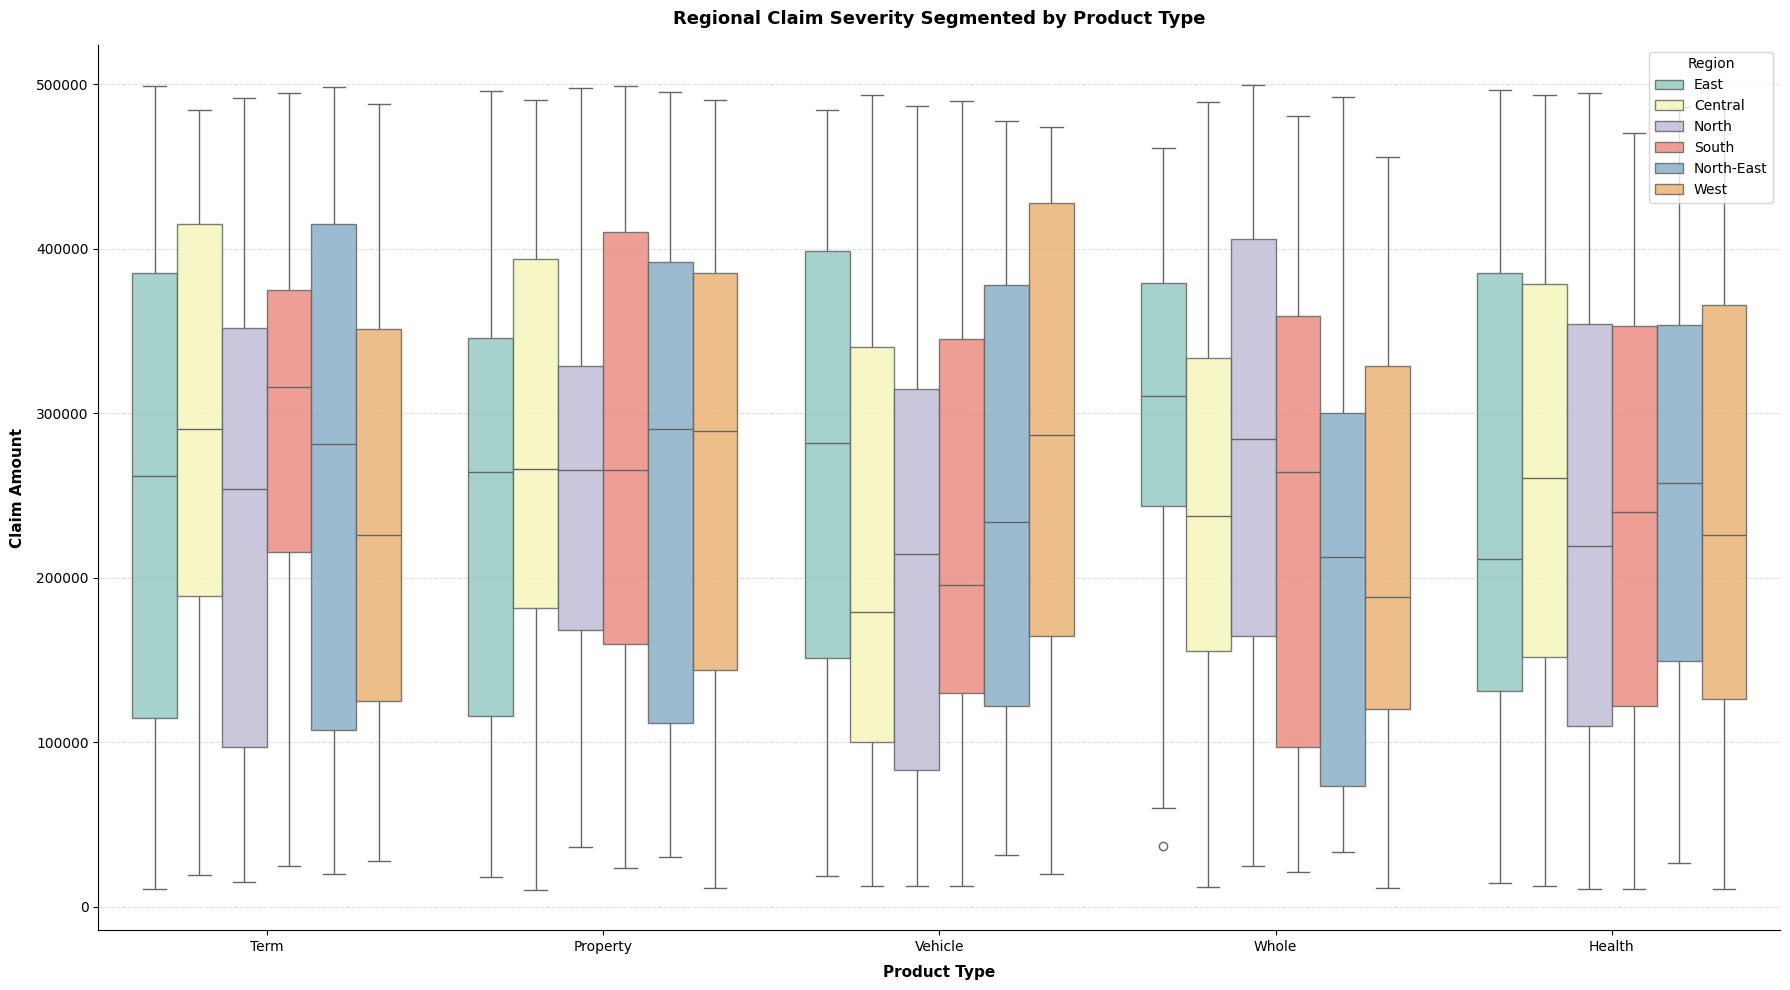

In [82]:
plt.figure(figsize=(18, 10))

sns.boxplot(
    data=df_claimed_only,
    x='product_type',
    y='claim_amount',
    hue='region',
    palette='Set3',
    boxprops=dict(alpha=0.85))

plt.title('Regional Claim Severity Segmented by Product Type',fontsize=13,fontweight='bold',pad=15)
plt.xlabel('Product Type', fontsize=11, fontweight='bold', labelpad=8)
plt.ylabel('Claim Amount', fontsize=11, fontweight='bold', labelpad=8)
plt.legend(title='Region', frameon=True, facecolor='white', loc='upper right')
plt.grid(axis='y', linestyle='--', alpha=0.4)

sns.despine()
plt.tight_layout()
plt.show()

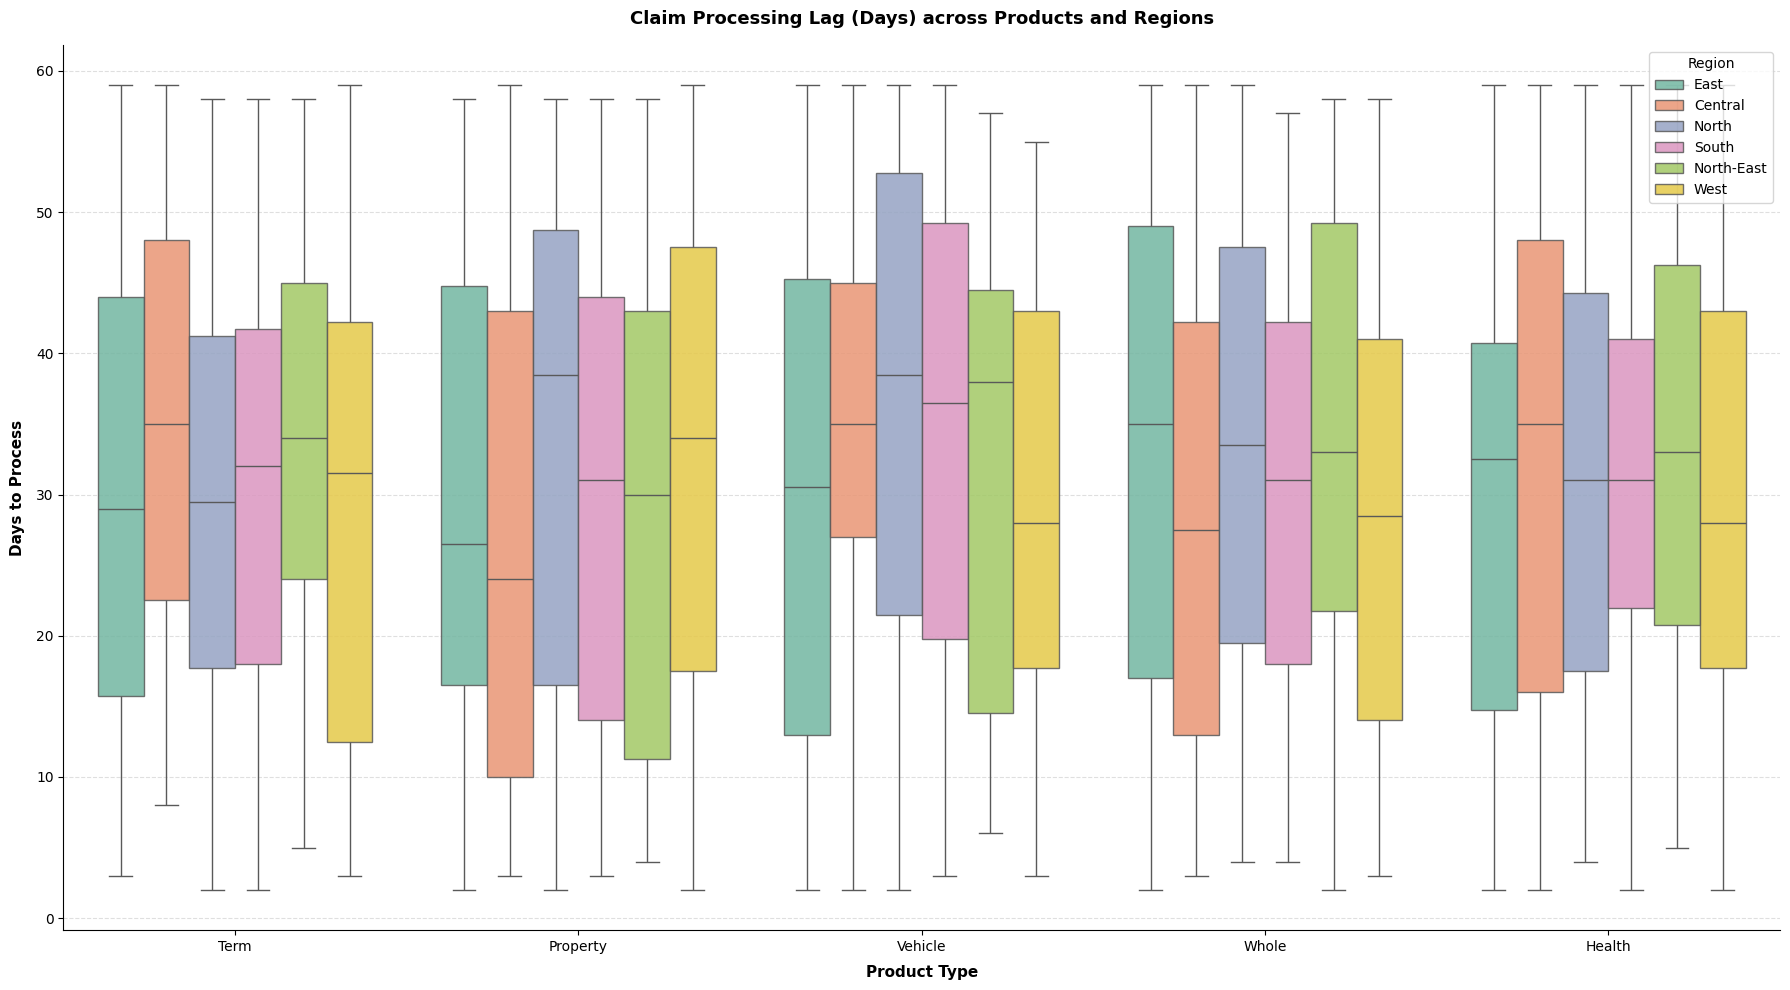

In [83]:
plt.figure(figsize=(18, 10))

sns.boxplot(
    data=df_claimed_only,
    x='product_type',
    y='days_to_process',
    hue='region',
    palette='Set2',
    boxprops=dict(alpha=0.85))

plt.title('Claim Processing Lag (Days) across Products and Regions',fontsize=13,fontweight='bold',pad=15,)
plt.xlabel('Product Type', fontsize=11, fontweight='bold', labelpad=8)
plt.ylabel('Days to Process', fontsize=11, fontweight='bold', labelpad=8)
plt.legend(title='Region', frameon=True, facecolor='white', loc='upper right')
plt.grid(axis='y', linestyle='--', alpha=0.4)

sns.despine()
plt.tight_layout()
plt.show()

In [84]:
avg_risk_rate_by_marital_status = df_customer_master[["marital_status","risk_score"]
                                                    ].groupby("marital_status").mean().reset_index()
avg_risk_rate_by_marital_status

,marital_status,risk_score
0,Divorced,0.513308
1,Married,0.489426
2,Single,0.485469


In [85]:
avg_risk_rate_by_occupation = df_customer_master[["occupation","risk_score"]
                                                    ].groupby("occupation").mean().reset_index()
avg_risk_rate_by_occupation

,occupation,risk_score
0,Retired,0.504495
1,Salaried,0.505407
2,Self-employed,0.497970
3,Student,0.476112


In [86]:
avg_risk_rate_by_region = df_customer_master[["region","risk_score"]
                                                    ].groupby("region").mean().reset_index()
avg_risk_rate_by_region

,region,risk_score
0,Central,0.492091
1,East,0.500330
2,North,0.505018
3,North-East,0.493898
4,South,0.501000
5,West,0.482667


In [87]:
df_customer_master[["smoking_status","risk_score"]].groupby("smoking_status").mean().reset_index()

,smoking_status,risk_score
0,No,0.505649
1,Yes,0.485082


In [88]:
df_customer_master[["pre_existing_illness","risk_score"]].groupby("pre_existing_illness").mean().reset_index()

,pre_existing_illness,risk_score
0,No,0.491261
1,Yes,0.500255


In [89]:
df_customer_master["risk_score"].mean()

np.float64(0.495752427184466)

### Insights:
Surprisingly Customer who smoke and who have pre existing illness before buying policy both have `risk_score` very close to mean of `risk_score`

In [90]:
df_agent_info.head()

,agent_id,region,join_date,total_policies_sold,lapsed_policies,avg_premium_sold,fraud_association,lapse_rate_pct,fraud_rate_pct,estimate_premium_book,sales_tier_estimate,lapse_rate_category
0,AGT5000,North,2016-02-15,196,42,37018.35,8,21.43,4.08,7255596.60,High,High
1,AGT5001,North,2016-09-05,189,28,48370.36,5,14.81,2.65,9141998.04,High,Medium
2,AGT5002,South,2016-06-26,66,0,10489.65,3,0.00,4.55,692316.90,Low,Low
3,AGT5003,North-East,2016-04-23,250,3,12415.84,6,1.20,2.40,3103960.00,Low,Low
4,AGT5004,South,2022-11-16,263,69,24057.14,4,26.24,1.52,6327027.82,Medium,High


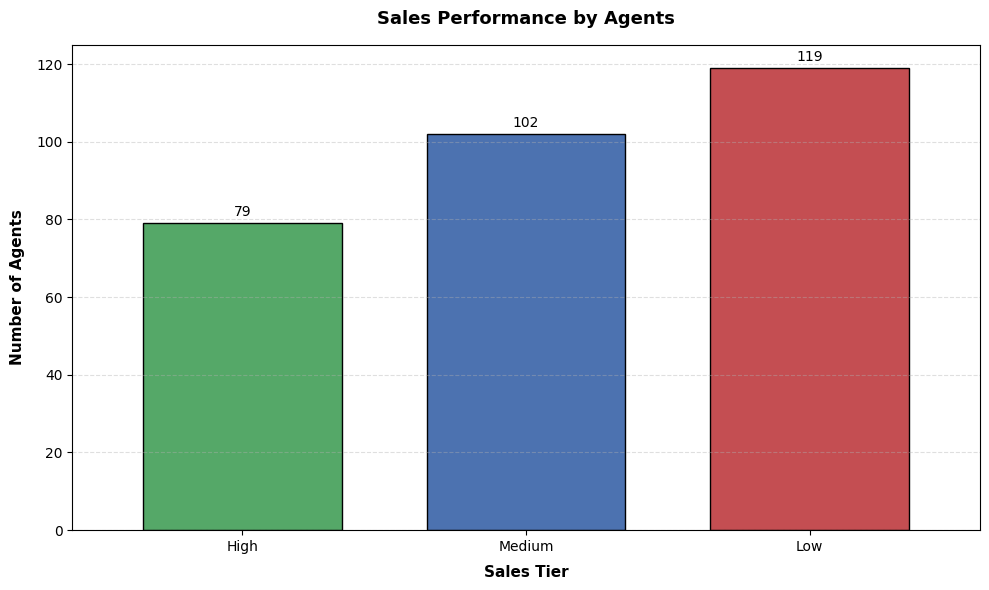

In [91]:
order = ['High',"Medium","Low"]

sales_tier_estimate_count = (df_agent_info.groupby("sales_tier_estimate")["agent_id"].count().reindex(order))

ax = sales_tier_estimate_count.plot(
    kind='bar',
    figsize=(10, 6),
    color=['#55A868','#4C72B0','#C44E52'],
    width=0.7,
    edgecolor='black')

plt.title('Sales Performance by Agents',fontsize=13,fontweight='bold',pad=15)
plt.xlabel('Sales Tier', fontsize=11, fontweight='bold', labelpad=8)
plt.ylabel('Number of Agents', fontsize=11, fontweight='bold', labelpad=8)
plt.xticks(rotation=0)
plt.grid(axis='y', linestyle='--', alpha=0.4)

for c in ax.containers:
    ax.bar_label(c, padding=3)

plt.tight_layout()
plt.show()

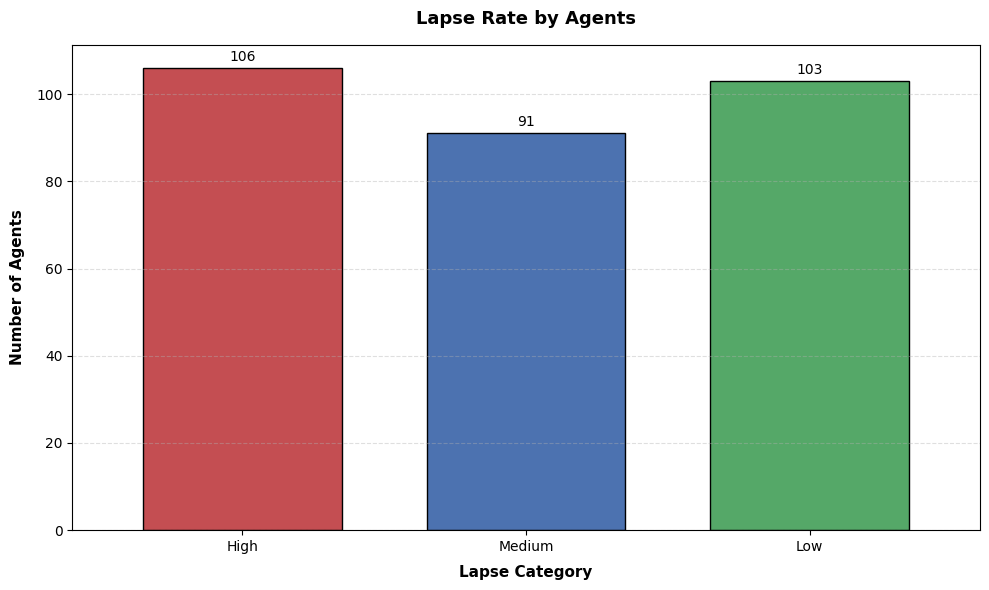

In [92]:
order = ['High',"Medium","Low"]

lapse_rate_count = (df_agent_info.groupby("lapse_rate_category")["agent_id"].nunique().reindex(order))

ax = lapse_rate_count.plot(
    kind='bar',
    figsize=(10, 6),
    color=['#C44E52', '#4C72B0', '#55A868'],
    width=0.7,
    edgecolor='black')

plt.title('Lapse Rate by Agents',fontsize=13,fontweight='bold',pad=15)
plt.xlabel('Lapse Category', fontsize=11, fontweight='bold', labelpad=8)
plt.ylabel('Number of Agents', fontsize=11, fontweight='bold', labelpad=8)
plt.xticks(rotation=0)
plt.grid(axis='y', linestyle='--', alpha=0.4)

for c in ax.containers:
    ax.bar_label(c, padding=3)

plt.tight_layout()
plt.show()

In [93]:
df_agent_info.head()

,agent_id,region,join_date,total_policies_sold,lapsed_policies,avg_premium_sold,fraud_association,lapse_rate_pct,fraud_rate_pct,estimate_premium_book,sales_tier_estimate,lapse_rate_category
0,AGT5000,North,2016-02-15,196,42,37018.35,8,21.43,4.08,7255596.60,High,High
1,AGT5001,North,2016-09-05,189,28,48370.36,5,14.81,2.65,9141998.04,High,Medium
2,AGT5002,South,2016-06-26,66,0,10489.65,3,0.00,4.55,692316.90,Low,Low
3,AGT5003,North-East,2016-04-23,250,3,12415.84,6,1.20,2.40,3103960.00,Low,Low
4,AGT5004,South,2022-11-16,263,69,24057.14,4,26.24,1.52,6327027.82,Medium,High


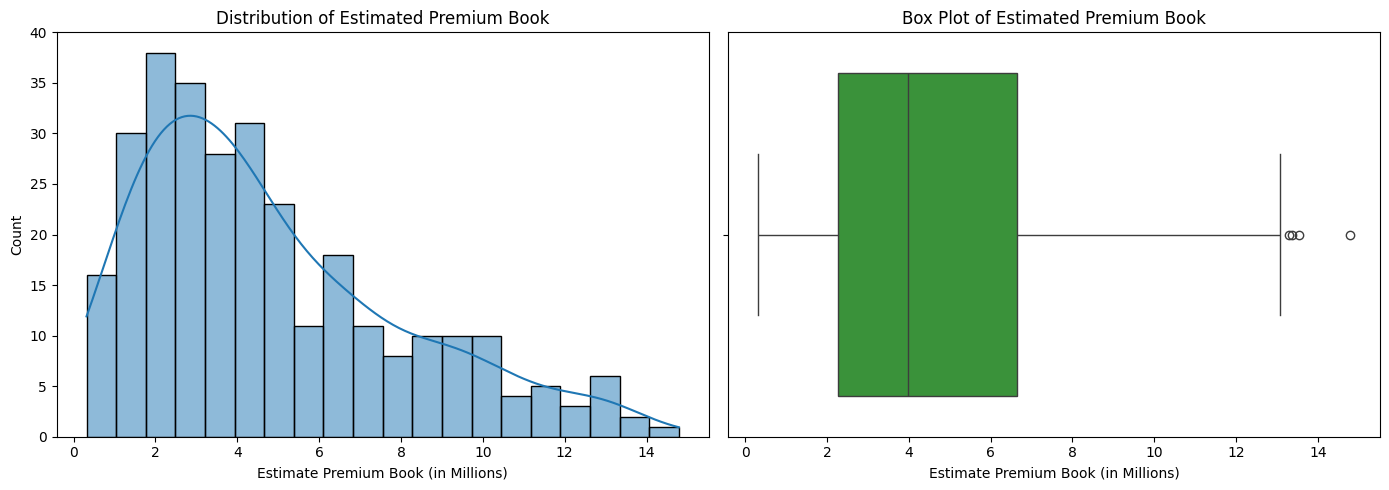

In [94]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
premium_in_millions = df_agent_info["estimate_premium_book"] / 1e6

sns.histplot(
    data=df_agent_info,
    x=premium_in_millions,
    kde=True,
    ax=axes[0],
    color="#1f77b4",
    bins=20)

axes[0].set_title("Distribution of Estimated Premium Book", fontsize=12)
axes[0].set_xlabel("Estimate Premium Book (in Millions)", fontsize=10)
axes[0].set_ylabel("Count", fontsize=10)
axes[0].set_ylim(0, 40)

sns.boxplot(
    data=df_agent_info,
    x=premium_in_millions,
    ax=axes[1],
    color="#2ca02c",
    flierprops=dict(marker="o", color="red", markersize=6))

axes[1].set_title("Box Plot of Estimated Premium Book", fontsize=12)
axes[1].set_xlabel("Estimate Premium Book (in Millions)", fontsize=10)

plt.tight_layout()
plt.show()

In [95]:
Q1 = df_agent_info["estimate_premium_book"].quantile(0.25)
Q3 = df_agent_info["estimate_premium_book"].quantile(0.75)
IQR = Q3 - Q1

upper_bound = Q3 + 1.5 * IQR
lower_bound = Q1 - 1.5 * IQR

outliers = df_agent_info[
    (df_agent_info["estimate_premium_book"] < lower_bound)| (df_agent_info["estimate_premium_book"] > upper_bound)
]

print(f"Upper Bound: {upper_bound:,.2f}")
print(f"Total Outliers Found: {len(outliers)}")
display(outliers[["agent_id","total_policies_sold","avg_premium_sold","estimate_premium_book"]])

Upper Bound: 13,194,507.45
Total Outliers Found: 4


,agent_id,total_policies_sold,avg_premium_sold,estimate_premium_book
45,AGT5045,281,47522.40,13353794.40
188,AGT5188,296,49968.47,14790667.12
194,AGT5194,272,49719.67,13523750.24
206,AGT5206,268,49548.01,13278866.68


According to boxplot and histogram we can see there are 4 agents who are outliers, but after reviewing the data again we can notice that those 4 agents has outperfom other agents in terms of estimate_premium booking. Thus instead of treating them as outliers we have to accept it because is shows their actual performance rather than any mistake in data

In [96]:
df_claim_history

,claim_id,policy_id,claim_date,month,year,claim_type,claim_amount,claim_status,payout_amount,claim_value,days_to_process,processing_speed,fraud_flag,approved_flag,rejected_flag,fraud_flag_numeric
0,CLM70003,POL51902,2022-10-10,10,2022,Theft,379127.79,Pending,0.00,High,40,Slow,No,0,0,0
1,CLM70004,POL50001,2021-12-06,12,2021,Hospital,431984.06,Approved,431984.06,High,56,Very Slow,No,1,0,0
2,CLM70005,POL53707,2024-07-17,7,2024,Death,206765.82,Rejected,0.00,Medium,39,Slow,No,0,1,0
3,CLM70006,POL53642,2024-06-12,6,2024,Accident,225358.05,Approved,225358.05,Medium,22,Moderate,Yes,1,0,1
4,CLM70007,POL51744,2024-06-13,6,2024,Theft,340208.27,Rejected,0.00,High,31,Slow,No,0,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1401,CLM71991,POL50232,2024-09-22,9,2024,Other,399400.01,Rejected,0.00,High,50,Very Slow,No,0,1,0
1402,CLM71994,POL51511,2024-01-29,1,2024,Hospital,109732.19,Rejected,0.00,Low,41,Slow,Yes,0,1,1
1403,CLM71997,POL51754,2024-02-13,2,2024,Accident,438345.46,Approved,438345.46,High,46,Very Slow,No,1,0,0
1404,CLM71998,POL52975,2022-03-30,3,2022,Other,373093.50,Rejected,0.00,High,23,Moderate,No,0,1,0


In [97]:
df_policy_details

,policy_id,customer_id,product_type,coverage_amount,annual_premium,premium_rate,policy_start_date,policy_end_date,policy_duration_days,agent_id,status,active_flag
0,POL50001,CUST10833,Property,169869.71,27193.94,16.01,2021-07-25,2022-10-25,457,AGT5238,Active,1
1,POL50002,CUST11786,Health,546514.84,19603.44,3.59,2022-09-19,2024-04-29,588,AGT5008,Cancelled,0
2,POL50003,CUST10501,Property,944249.15,36274.58,3.84,2022-12-08,2025-04-23,867,AGT5118,Cancelled,0
3,POL50004,CUST10349,Property,209475.32,23091.58,11.02,2024-04-09,2024-07-20,102,AGT5090,Active,1
4,POL50005,CUST12296,Term,887938.35,10458.22,1.18,2022-10-08,2024-12-12,796,AGT5050,Lapsed,0
...,...,...,...,...,...,...,...,...,...,...,...,...
2823,POL53991,CUST10002,Property,300039.56,33337.52,11.11,2022-08-26,2023-05-26,273,AGT5262,Lapsed,0
2824,POL53994,CUST12172,Term,329263.38,13782.59,4.19,2023-11-10,2025-07-01,599,AGT5276,Cancelled,0
2825,POL53996,CUST11829,Property,139846.91,15519.76,11.10,2022-10-04,2024-01-29,482,AGT5207,Cancelled,0
2826,POL53998,CUST12139,Health,165202.48,35222.07,21.32,2021-01-12,2023-02-18,767,AGT5213,Cancelled,0


In [98]:
policy_claim_metrics = (df_claim_history.groupby('policy_id', as_index=False).agg(
        total_claims=('claim_id', 'count'),
        approved_claims=('approved_flag', 'sum'),
        total_submitted_amount=('claim_amount', 'sum'),
        payout_amount=('payout_amount', 'sum'),
        fraud_claims=('fraud_flag_numeric', 'sum')))

policy_claim_metrics

,policy_id,total_claims,approved_claims,total_submitted_amount,payout_amount,fraud_claims
0,POL50001,2,1,882061.96,431984.06,0
1,POL50002,2,0,384914.12,0.00,2
2,POL50006,1,1,291861.00,291861.00,0
3,POL50007,1,1,33165.30,33165.30,0
4,POL50013,1,0,382996.34,0.00,0
...,...,...,...,...,...,...
1125,POL53985,1,1,176398.55,176398.55,0
1126,POL53987,1,0,186652.35,0.00,0
1127,POL53990,1,0,128223.46,0.00,0
1128,POL53994,1,0,452035.42,0.00,0


### Merging dataframe, while insuring that the level of details is policy level.

In [99]:
df_policy_claim_analysis = (
    df_policy_details.merge(
        df_customer_master[[
            'customer_id',
            'region',
            'marital_status',
            'occupation',
            'smoking_status',
            'risk_category',
            'risk_score'
        ]],
        on='customer_id',
        how='left',
        validate='many_to_one'
    ).merge(
        policy_claim_metrics,
        on='policy_id',
        how='left',
        validate='one_to_one'
    )
)


df_policy_claim_analysis.head()

,policy_id,customer_id,product_type,coverage_amount,annual_premium,premium_rate,policy_start_date,policy_end_date,policy_duration_days,agent_id,...,marital_status,occupation,smoking_status,risk_category,risk_score,total_claims,approved_claims,total_submitted_amount,payout_amount,fraud_claims
0,POL50001,CUST10833,Property,169869.71,27193.94,16.01,2021-07-25,2022-10-25,457,AGT5238,...,Divorced,Student,Yes,Medium,0.56,2.0,1.0,882061.96,431984.06,0.0
1,POL50002,CUST11786,Health,546514.84,19603.44,3.59,2022-09-19,2024-04-29,588,AGT5008,...,Single,Salaried,No,High,0.67,2.0,0.0,384914.12,0.00,2.0
2,POL50003,CUST10501,Property,944249.15,36274.58,3.84,2022-12-08,2025-04-23,867,AGT5118,...,Single,Retired,Yes,High,0.69,NaN,NaN,NaN,NaN,NaN
3,POL50004,CUST10349,Property,209475.32,23091.58,11.02,2024-04-09,2024-07-20,102,AGT5090,...,Married,Self-employed,No,Medium,0.60,NaN,NaN,NaN,NaN,NaN
4,POL50005,CUST12296,Term,887938.35,10458.22,1.18,2022-10-08,2024-12-12,796,AGT5050,...,Single,Student,Yes,Medium,0.55,NaN,NaN,NaN,NaN,NaN


In [100]:
claim_cols = ['total_claims', 'approved_claims', 'total_submitted_amount', 'payout_amount', 'fraud_claims']

df_policy_claim_analysis[claim_cols] = df_policy_claim_analysis[claim_cols].fillna(0)
df_policy_claim_analysis[['total_claims', 'approved_claims', 'fraud_claims']] = (
    df_policy_claim_analysis[['total_claims', 'approved_claims', 'fraud_claims']].astype(int)
)

df_policy_claim_analysis.info()

<class 'pandas.DataFrame'>
RangeIndex: 2828 entries, 0 to 2827
Data columns (total 23 columns):
 #   Column                  Non-Null Count  Dtype        
---  ------                  --------------  -----        
 0   policy_id               2828 non-null   str          
 1   customer_id             2828 non-null   str          
 2   product_type            2828 non-null   str          
 3   coverage_amount         2828 non-null   float64      
 4   annual_premium          2828 non-null   float64      
 5   premium_rate            2828 non-null   float64      
 6   policy_start_date       2828 non-null   datetime64[s]
 7   policy_end_date         2828 non-null   datetime64[s]
 8   policy_duration_days    2828 non-null   int64        
 9   agent_id                2828 non-null   str          
 10  status                  2828 non-null   str          
 11  active_flag             2828 non-null   int64        
 12  region                  2828 non-null   str          
 13  marital_status

In [101]:
df_policy_claim_analysis

,policy_id,customer_id,product_type,coverage_amount,annual_premium,premium_rate,policy_start_date,policy_end_date,policy_duration_days,agent_id,...,marital_status,occupation,smoking_status,risk_category,risk_score,total_claims,approved_claims,total_submitted_amount,payout_amount,fraud_claims
0,POL50001,CUST10833,Property,169869.71,27193.94,16.01,2021-07-25,2022-10-25,457,AGT5238,...,Divorced,Student,Yes,Medium,0.56,2,1,882061.96,431984.06,0
1,POL50002,CUST11786,Health,546514.84,19603.44,3.59,2022-09-19,2024-04-29,588,AGT5008,...,Single,Salaried,No,High,0.67,2,0,384914.12,0.00,2
2,POL50003,CUST10501,Property,944249.15,36274.58,3.84,2022-12-08,2025-04-23,867,AGT5118,...,Single,Retired,Yes,High,0.69,0,0,0.00,0.00,0
3,POL50004,CUST10349,Property,209475.32,23091.58,11.02,2024-04-09,2024-07-20,102,AGT5090,...,Married,Self-employed,No,Medium,0.60,0,0,0.00,0.00,0
4,POL50005,CUST12296,Term,887938.35,10458.22,1.18,2022-10-08,2024-12-12,796,AGT5050,...,Single,Student,Yes,Medium,0.55,0,0,0.00,0.00,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2823,POL53991,CUST10002,Property,300039.56,33337.52,11.11,2022-08-26,2023-05-26,273,AGT5262,...,Single,Student,Yes,Medium,0.48,0,0,0.00,0.00,0
2824,POL53994,CUST12172,Term,329263.38,13782.59,4.19,2023-11-10,2025-07-01,599,AGT5276,...,Married,Student,No,Medium,0.46,1,0,452035.42,0.00,0
2825,POL53996,CUST11829,Property,139846.91,15519.76,11.10,2022-10-04,2024-01-29,482,AGT5207,...,Single,Salaried,No,Medium,0.37,0,0,0.00,0.00,0
2826,POL53998,CUST12139,Health,165202.48,35222.07,21.32,2021-01-12,2023-02-18,767,AGT5213,...,Single,Self-employed,No,High,0.80,0,0,0.00,0.00,0


In [102]:
print("Policies in policy table:", len(df_policy_details))
print("Rows in analysis table:", len(df_policy_claim_analysis))

Policies in policy table: 2828
Rows in analysis table: 2828


#### Now creating grouped dataframes to compare approved amount and rate

In [103]:
df_region_claim_ratio = (
    df_policy_claim_analysis
    .groupby('region', as_index=False).agg(policies=('policy_id', 'nunique'),
                                           total_claimed_amount=('total_submitted_amount', 'sum'),
                                           total_annual_premium=('annual_premium','sum'),
                                           approved_payout=('payout_amount', 'sum'),
                                           total_claims=('total_claims', 'sum'),
                                           approved_claims=('approved_claims', 'sum'))
)


df_region_claim_ratio['loss_ratio_pct'] = (
    df_region_claim_ratio['approved_payout'] /
    df_region_claim_ratio['total_annual_premium'] * 100).round(2)


df_region_claim_ratio['claim_frequency_pct'] = (
    df_region_claim_ratio['total_claims'] /
    df_region_claim_ratio['policies'] * 100).round(2)

df_region_claim_ratio["approved_rate_pct"] = (
    df_region_claim_ratio["approved_claims"]/
    df_region_claim_ratio["total_claims"]*100).round(2)

df_region_claim_ratio

,region,policies,total_claimed_amount,total_annual_premium,approved_payout,total_claims,approved_claims,loss_ratio_pct,claim_frequency_pct,approved_rate_pct
0,Central,494,64852645.21,13158188.35,25275713.07,254,94,192.09,51.42,37.01
1,East,456,61725106.45,12572921.23,23058665.66,237,88,183.40,51.97,37.13
2,North,490,55596617.57,13080190.33,20370126.56,230,90,155.73,46.94,39.13
3,North-East,440,47685864.84,11727087.08,14547435.39,192,60,124.05,43.64,31.25
4,South,439,60948673.22,11691996.63,24222557.83,232,88,207.17,52.85,37.93
5,West,509,64814090.46,13235891.62,19914186.20,261,84,150.46,51.28,32.18


In [104]:
df_product_claim_ratio = (
    df_policy_claim_analysis
    .groupby('product_type', as_index=False).agg(policies=('policy_id', 'nunique'),
                                           total_claimed_amount=('total_submitted_amount', 'sum'),
                                            total_annual_premium=('annual_premium','sum'),
                                           approved_payout=('payout_amount', 'sum'),
                                           total_claims=('total_claims', 'sum'),
                                           approved_claims=('approved_claims', 'sum'))
)


df_product_claim_ratio['loss_ratio_pct'] = (
    df_product_claim_ratio['approved_payout'] /
    df_product_claim_ratio['total_annual_premium'] * 100).round(2)


df_product_claim_ratio['claim_frequency_pct'] = (
    df_product_claim_ratio['total_claims'] /
    df_product_claim_ratio['policies'] * 100).round(2)

df_product_claim_ratio["approved_rate_pct"] = (
    df_product_claim_ratio["approved_claims"]/
    df_product_claim_ratio["total_claims"]*100).round(2)

df_product_claim_ratio

,product_type,policies,total_claimed_amount,total_annual_premium,approved_payout,total_claims,approved_claims,loss_ratio_pct,claim_frequency_pct,approved_rate_pct
0,Health,585,77777956.58,15456871.14,29158037.10,314,119,188.64,53.68,37.90
1,Property,567,75128333.72,14729902.02,21473940.11,285,84,145.78,50.26,29.47
2,Term,545,68210871.45,14790116.22,24180600.05,262,89,163.49,48.07,33.97
3,Vehicle,591,68532832.91,16070206.13,26971276.38,282,112,167.83,47.72,39.72
4,Whole,540,65973003.09,14419179.73,25604831.07,263,100,177.57,48.70,38.02


In [105]:
df_marital_status_claim_ratio = (
    df_policy_claim_analysis
    .groupby('marital_status', as_index=False).agg(policies=('policy_id', 'nunique'),
                                           total_claimed_amount=('total_submitted_amount', 'sum'),
                                            total_annual_premium=('annual_premium','sum'),
                                           approved_payout=('payout_amount', 'sum'),
                                           total_claims=('total_claims', 'sum'),
                                           approved_claims=('approved_claims', 'sum'))
)


df_marital_status_claim_ratio['loss_ratio_pct'] = (
    df_marital_status_claim_ratio['approved_payout'] /
    df_marital_status_claim_ratio['total_annual_premium'] * 100).round(2)


df_marital_status_claim_ratio['claim_frequency_pct'] = (
    df_marital_status_claim_ratio['total_claims'] /
    df_marital_status_claim_ratio['policies'] * 100).round(2)

df_marital_status_claim_ratio["approved_rate_pct"] = (
    df_marital_status_claim_ratio["approved_claims"]/
    df_marital_status_claim_ratio["total_claims"]*100).round(2)

df_marital_status_claim_ratio

,marital_status,policies,total_claimed_amount,total_annual_premium,approved_payout,total_claims,approved_claims,loss_ratio_pct,claim_frequency_pct,approved_rate_pct
0,Divorced,941,1.134677e+08,25305512.09,46393568.55,452,178,183.33,48.03,39.38
1,Married,922,1.174624e+08,24597570.10,35985074.75,451,142,146.30,48.92,31.49
2,Single,965,1.246929e+08,25563193.05,45010041.41,503,184,176.07,52.12,36.58


In [106]:
df_occupation_claim_ratio = (
    df_policy_claim_analysis
    .groupby('occupation', as_index=False).agg(policies=('policy_id', 'nunique'),
                                           total_claimed_amount=('total_submitted_amount', 'sum'),
                                           approved_payout=('payout_amount', 'sum'),
                                            total_annual_premium=('annual_premium','sum'),
                                           total_claims=('total_claims', 'sum'),
                                           approved_claims=('approved_claims', 'sum'))
)


df_occupation_claim_ratio['loss_ratio_pct'] = (
    df_occupation_claim_ratio['approved_payout'] /
    df_occupation_claim_ratio['total_annual_premium'] * 100).round(2)


df_occupation_claim_ratio['claim_frequency_pct'] = (
    df_occupation_claim_ratio['total_claims'] /
    df_occupation_claim_ratio['policies'] * 100).round(2)

df_occupation_claim_ratio["approved_rate_pct"] = (
    df_occupation_claim_ratio["approved_claims"]/
    df_occupation_claim_ratio["total_claims"]*100).round(2)

df_occupation_claim_ratio

,occupation,policies,total_claimed_amount,approved_payout,total_annual_premium,total_claims,approved_claims,loss_ratio_pct,claim_frequency_pct,approved_rate_pct
0,Retired,747,95143959.15,34315136.61,19947265.48,378,141,172.03,50.60,37.30
1,Salaried,633,75510025.82,27578451.51,16900836.09,288,100,163.18,45.50,34.72
2,Self-employed,716,90345776.69,30281052.42,19274943.03,353,119,157.10,49.30,33.71
3,Student,732,94623236.09,35214044.17,19343230.64,387,144,182.05,52.87,37.21


In [107]:
df_smoking_status_claim_ratio = (
    df_policy_claim_analysis
    .groupby('smoking_status', as_index=False).agg(policies=('policy_id', 'nunique'),
                                           total_claimed_amount=('total_submitted_amount', 'sum'),
                                            total_annual_premium=('annual_premium','sum'),
                                           approved_payout=('payout_amount', 'sum'),
                                           total_claims=('total_claims', 'sum'),
                                           approved_claims=('approved_claims', 'sum'))
)


df_smoking_status_claim_ratio['loss_ratio_pct'] = (
    df_smoking_status_claim_ratio['approved_payout'] /
    df_smoking_status_claim_ratio['total_annual_premium'] * 100).round(2)


df_smoking_status_claim_ratio['claim_frequency_pct'] = (
    df_smoking_status_claim_ratio['total_claims'] /
    df_smoking_status_claim_ratio['policies'] * 100).round(2)

df_smoking_status_claim_ratio["approved_rate_pct"] = (
    df_smoking_status_claim_ratio["approved_claims"]/
    df_smoking_status_claim_ratio["total_claims"]*100).round(2)

df_smoking_status_claim_ratio

,smoking_status,policies,total_claimed_amount,total_annual_premium,approved_payout,total_claims,approved_claims,loss_ratio_pct,claim_frequency_pct,approved_rate_pct
0,No,1417,1.665270e+08,37642970.39,56861009.82,678,238,151.05,47.85,35.10
1,Yes,1411,1.890960e+08,37823304.85,70527674.89,728,266,186.47,51.59,36.54


In [108]:
df_region_claim_ratio

,region,policies,total_claimed_amount,total_annual_premium,approved_payout,total_claims,approved_claims,loss_ratio_pct,claim_frequency_pct,approved_rate_pct
0,Central,494,64852645.21,13158188.35,25275713.07,254,94,192.09,51.42,37.01
1,East,456,61725106.45,12572921.23,23058665.66,237,88,183.40,51.97,37.13
2,North,490,55596617.57,13080190.33,20370126.56,230,90,155.73,46.94,39.13
3,North-East,440,47685864.84,11727087.08,14547435.39,192,60,124.05,43.64,31.25
4,South,439,60948673.22,11691996.63,24222557.83,232,88,207.17,52.85,37.93
5,West,509,64814090.46,13235891.62,19914186.20,261,84,150.46,51.28,32.18


In [109]:
overall_loss_ratio_pct = (
    df_policy_claim_analysis['payout_amount'].sum() /
    df_policy_claim_analysis['annual_premium'].sum() * 100
)

def add_driver_metrics(df, group_column):
    df = df.copy()

    df['payout_premium_gap'] = (
        df['approved_payout'] - df['total_annual_premium']
    ).round(2)

    df['payout_share_pct'] = (
        df['approved_payout'] / df['approved_payout'].sum() * 100
    ).round(2)

    df['premium_share_pct'] = (
        df['total_annual_premium'] / df['total_annual_premium'].sum() * 100
    ).round(2)

    return df.sort_values(
        ['payout_premium_gap', 'loss_ratio_pct'],
        ascending=False
    )

In [110]:
region_driver_df = add_driver_metrics(
    df_region_claim_ratio, 'region'
)
region_driver_df

,region,policies,total_claimed_amount,total_annual_premium,approved_payout,total_claims,approved_claims,loss_ratio_pct,claim_frequency_pct,approved_rate_pct,payout_premium_gap,payout_share_pct,premium_share_pct
4,South,439,60948673.22,11691996.63,24222557.83,232,88,207.17,52.85,37.93,12530561.20,19.01,15.49
0,Central,494,64852645.21,13158188.35,25275713.07,254,94,192.09,51.42,37.01,12117524.72,19.84,17.44
1,East,456,61725106.45,12572921.23,23058665.66,237,88,183.40,51.97,37.13,10485744.43,18.10,16.66
2,North,490,55596617.57,13080190.33,20370126.56,230,90,155.73,46.94,39.13,7289936.23,15.99,17.33
5,West,509,64814090.46,13235891.62,19914186.20,261,84,150.46,51.28,32.18,6678294.58,15.63,17.54
3,North-East,440,47685864.84,11727087.08,14547435.39,192,60,124.05,43.64,31.25,2820348.31,11.42,15.54


In [111]:
list[region_driver_df.columns]

list[Index(['region', 'policies', 'total_claimed_amount', 'total_annual_premium',
       'approved_payout', 'total_claims', 'approved_claims', 'loss_ratio_pct',
       'claim_frequency_pct', 'approved_rate_pct', 'payout_premium_gap',
       'payout_share_pct', 'premium_share_pct'],
      dtype='str')]

In [112]:
region_driver_df = region_driver_df[['region',
                                     'policies',
                                     'total_claimed_amount',
                                     'total_annual_premium',
                                     'approved_payout',
                                     'total_claims',
                                     'approved_claims',
                                     'claim_frequency_pct',
                                     'approved_rate_pct',
                                     'payout_premium_gap',
                                     'loss_ratio_pct',
                                     'payout_share_pct',
                                     'premium_share_pct']]
region_driver_df

,region,policies,total_claimed_amount,total_annual_premium,approved_payout,total_claims,approved_claims,claim_frequency_pct,approved_rate_pct,payout_premium_gap,loss_ratio_pct,payout_share_pct,premium_share_pct
4,South,439,60948673.22,11691996.63,24222557.83,232,88,52.85,37.93,12530561.20,207.17,19.01,15.49
0,Central,494,64852645.21,13158188.35,25275713.07,254,94,51.42,37.01,12117524.72,192.09,19.84,17.44
1,East,456,61725106.45,12572921.23,23058665.66,237,88,51.97,37.13,10485744.43,183.40,18.10,16.66
2,North,490,55596617.57,13080190.33,20370126.56,230,90,46.94,39.13,7289936.23,155.73,15.99,17.33
5,West,509,64814090.46,13235891.62,19914186.20,261,84,51.28,32.18,6678294.58,150.46,15.63,17.54
3,North-East,440,47685864.84,11727087.08,14547435.39,192,60,43.64,31.25,2820348.31,124.05,11.42,15.54


C:\Users\lokes\AppData\Local\Temp\ipykernel_19308\3073488587.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(


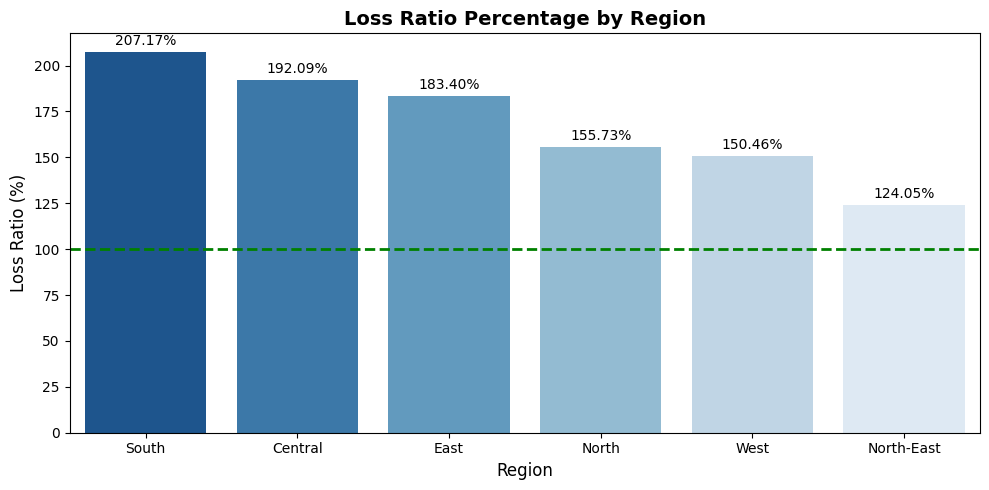

In [113]:
region_sorted = region_driver_df.sort_values(by='loss_ratio_pct', ascending=False)

plt.figure(figsize=(10, 5))
ax = sns.barplot(
    data=region_sorted,
    x='region',
    y='loss_ratio_pct',
    palette='Blues_r'
)

plt.axhline(y=100,color="green",linestyle="--",linewidth=2)
plt.title('Loss Ratio Percentage by Region', fontsize=14, fontweight='bold')
plt.xlabel('Region', fontsize=12)
plt.ylabel('Loss Ratio (%)', fontsize=12)
plt.xticks(rotation=0)


for c in ax.containers:
    ax.bar_label(c, fmt='%.2f%%', padding=3)

plt.tight_layout()
plt.show()

In [114]:
df_policy_claim_analysis['has_approved_claim'] = (
    df_policy_claim_analysis['approved_claims'] > 0
).astype(int)

In [115]:
total_policy = df_policy_claim_analysis['policy_id'].nunique()
total_annual_premium_M = (df_policy_claim_analysis['annual_premium'].sum() / 1e6).round(2)
total_claimed_amount_M = (df_policy_claim_analysis['total_submitted_amount'].sum() / 1e6).round(2)
total_approved_payout_M = (df_policy_claim_analysis['payout_amount'].sum() / 1e6).round(2)
loss_ratio = (df_policy_claim_analysis['payout_amount'].sum() / df_policy_claim_analysis['annual_premium'].sum()*100).round(4)

overall_policy_kpi_df = pd.DataFrame({
    'KPI' :[
        'Total Policy',
        'Total Annual Premium(M)',
        'Total Claimed Amount(M)',
        'Total Approved Amount(M)',
        'Loss Ration(%)'
    ],
    'Values':[
        total_policy,
        total_annual_premium_M.round(2),
        total_claimed_amount_M.round(2),
        total_approved_payout_M.round(2),
        loss_ratio
    ]
})
display(overall_policy_kpi_df)

,KPI,Values
0,Total Policy,2828.0000
1,Total Annual Premium(M),75.4700
2,Total Claimed Amount(M),355.6200
3,Total Approved Amount(M),127.3900
4,Loss Ration(%),168.8021


In [116]:
agent_region_df = (df_agent_info[['agent_id', 'region']].rename(columns={'region': 'agent_region'}))

# One row per claim
df_claim_fraud_analysis = (
    df_claim_history
    .merge(df_policy_details[
        ['policy_id',
         'customer_id',
         'agent_id',
         'product_type']],
        on='policy_id',
        how='left',
        validate='many_to_one'
    )
    .merge(df_customer_master[
        ['customer_id',
         'region',
         'marital_status',
         'occupation',
         'smoking_status',
         'risk_score']],
        on='customer_id',
        how='left',
        validate='many_to_one'
    )
    .merge(agent_region_df,
        on='agent_id',
        how='left',
        validate='many_to_one'
    )
)

df_claim_fraud_analysis['is_fraud'] = (df_claim_fraud_analysis['fraud_flag'] == 'Yes').astype(int)

# Data-quality checks
assert len(df_claim_fraud_analysis) == len(df_claim_history)
assert df_claim_fraud_analysis['claim_id'].is_unique

print("Claim-level fraud analysis DataFrame created successfully.")
display(df_claim_fraud_analysis.head())

Claim-level fraud analysis DataFrame created successfully.


,claim_id,policy_id,claim_date,month,year,claim_type,claim_amount,claim_status,payout_amount,claim_value,...,customer_id,agent_id,product_type,region,marital_status,occupation,smoking_status,risk_score,agent_region,is_fraud
0,CLM70003,POL51902,2022-10-10,10,2022,Theft,379127.79,Pending,0.00,High,...,CUST11700,AGT5238,Term,East,Divorced,Student,No,0.29,West,0
1,CLM70004,POL50001,2021-12-06,12,2021,Hospital,431984.06,Approved,431984.06,High,...,CUST10833,AGT5238,Property,Central,Divorced,Student,Yes,0.56,West,0
2,CLM70005,POL53707,2024-07-17,7,2024,Death,206765.82,Rejected,0.00,Medium,...,CUST11843,AGT5073,Property,North,Divorced,Student,No,0.51,South,0
3,CLM70006,POL53642,2024-06-12,6,2024,Accident,225358.05,Approved,225358.05,Medium,...,CUST11314,AGT5128,Vehicle,East,Married,Self-employed,No,0.23,South,1
4,CLM70007,POL51744,2024-06-13,6,2024,Theft,340208.27,Rejected,0.00,High,...,CUST10557,AGT5144,Whole,South,Divorced,Self-employed,No,0.84,East,0


In [117]:
total_claims = df_claim_fraud_analysis['claim_id'].nunique()
fraud_claims = df_claim_fraud_analysis['is_fraud'].sum()
fraud_rate_pct = (fraud_claims / total_claims * 100)
approved_claims = (df_claim_fraud_analysis['claim_status'] == 'Approved').sum()
approval_rate_pct = (approved_claims / total_claims * 100)
avg_processing_days = (df_claim_fraud_analysis['days_to_process'].mean())

overall_claims_kpi_df = pd.DataFrame({
    'KPI': [
        'Total Claims',
        'Fraud Claims',
        'Fraud Rate (%)',
        'Approved Claims',
        'Approval Rate (%)',
        'Average Processing Days'
    ],
    'Value': [
        total_claims,
        fraud_claims,
        round(fraud_rate_pct, 2),
        approved_claims,
        round(approval_rate_pct, 2),
        round(avg_processing_days, 2)
    ]
})

display(overall_claims_kpi_df)

,KPI,Value
0,Total Claims,1406.00
1,Fraud Claims,689.00
2,Fraud Rate (%),49.00
3,Approved Claims,504.00
4,Approval Rate (%),35.85
5,Average Processing Days,31.17


# Business Questions

## Hypothesis Testing to Find Insights



### Business question: Are some customer regions associated with a higher rate of approved claims?

**H₀ (Null Hypothesis):** Region and approved-claim occurrence are independent.  
The approved-claim rate is the same across all regions.

**H₁ (Alternative Hypothesis):** Region and approved-claim occurrence are associated.  
At least one region has a different approved-claim rate.

**Test:** Chi-square test of independence  
**Significance level:** α = 0.05

In [118]:
import pandas as pd
import numpy as np
from scipy.stats import (chi2_contingency,kruskal,mannwhitneyu,spearmanr)

alpha = 0.05

region_test_df = df_policy_claim_analysis[['region', 'has_approved_claim']].dropna()

contingency_table = pd.crosstab(region_test_df['region'],region_test_df['has_approved_claim'])

print("Contingency Table:")
display(contingency_table)

chi2, p_value, dof, expected = chi2_contingency(contingency_table)
n = contingency_table.to_numpy().sum()

cramers_v = np.sqrt(chi2 / (n * min(contingency_table.shape[0] - 1,contingency_table.shape[1] - 1)))
min_expected_count = expected.min()

region_claim_rate_df = (
    region_test_df
    .groupby('region', as_index=False)
    .agg(
        total_policies=('has_approved_claim', 'count'),
        approved_claim_policies=('has_approved_claim', 'sum')
    )
)

region_claim_rate_df['approved_claim_rate_pct'] = (
    region_claim_rate_df['approved_claim_policies'] /
    region_claim_rate_df['total_policies'] * 100
).round(2)

region_claim_rate_df = region_claim_rate_df.sort_values('approved_claim_rate_pct',ascending=False).reset_index(drop=True)

print("\nApproved-Claim Rate by Region:")
display(region_claim_rate_df)

print("\nStatistical Test Results")
print("-" * 40)
print(f"Chi-square statistic: {chi2:.3f}")
print(f"Degrees of freedom: {dof}")
print(f"P-value: {p_value:.6f}")
print(f"Cramer's V: {cramers_v:.3f}")
print(f"Minimum expected cell count: {min_expected_count:.2f}")

print("Decision and Business Insight")
print("-" * 40)

highest_region = region_claim_rate_df.iloc[0]
lowest_region = region_claim_rate_df.iloc[-1]

if p_value < alpha:
    print("Decision: Reject H₀.")
    print("Conclusion: Region is significantly associated with approved-claim occurrence.")
    print(f"Highest approved-claim rate: {highest_region['region']} "
          f"({highest_region['approved_claim_rate_pct']:.2f}%).")
    print(f"Lowest approved-claim rate: {lowest_region['region']} "
          f"({lowest_region['approved_claim_rate_pct']:.2f}%).")
    print("Business insight: Regions with higher approved-claim rates should be prioritized for underwriting,"
          " pricing, and claims-review analysis.")
else:
    print("Decision: Fail to reject H₀.")
    print("Conclusion: There is no statistically significant evidence that approved-claim occurrence differs by region.")
    print("Business insight: Regional loss-ratio differences may be due to claim severity, premium levels,"
          " or random variation rather than claim incidence.")

Contingency Table:


has_approved_claim,0,1
region,,
Central,409,85
East,379,77
North,410,80
North-East,385,55
South,357,82
West,429,80



Approved-Claim Rate by Region:


,region,total_policies,approved_claim_policies,approved_claim_rate_pct
0,South,439,82,18.68
1,Central,494,85,17.21
2,East,456,77,16.89
3,North,490,80,16.33
4,West,509,80,15.72
5,North-East,440,55,12.50



Statistical Test Results
----------------------------------------
Chi-square statistic: 7.031
Degrees of freedom: 5
P-value: 0.218322
Cramer's V: 0.050
Minimum expected cell count: 71.25
Decision and Business Insight
----------------------------------------
Decision: Fail to reject H₀.
Conclusion: There is no statistically significant evidence that approved-claim occurrence differs by region.
Business insight: Regional loss-ratio differences may be due to claim severity, premium levels, or random variation rather than claim incidence.


Region does not drive claim approvals: You cannot say that being in a specific region significantly increases or decreases the likelihood of a policy having approved claims.

### Business Question: Are some insurance product types associated with a higher approved-claim rate?

**Null Hypothesis (H₀):** Product type and approved-claim occurrence are independent.  
The approved-claim rate is the same across all product types.

**Alternative Hypothesis (H₁):** Product type and approved-claim occurrence are associated.  
At least one product type has a different approved-claim rate.

**Test:** Chi-square test of independence.  
**Significance level:** α = 0.05

In [119]:
product_claim_test_df = df_policy_claim_analysis[['product_type', 'has_approved_claim']].dropna()

table = pd.crosstab(
    product_claim_test_df['product_type'],
    product_claim_test_df['has_approved_claim']
).reindex(columns=[0, 1], fill_value=0)


table.columns = ['Not Approved Claim','One or More Approved Claims']
display(table)


chi2, p_value, dof, expected = chi2_contingency(table)
n = table.to_numpy().sum()


cramers_v = np.sqrt(chi2 /(n *min(table.shape[0] - 1, table.shape[1] - 1)))

summary = (
    product_claim_test_df
    .groupby('product_type', as_index=False)
    .agg(
        policies=('has_approved_claim', 'count'),
        approved_claim_policies=('has_approved_claim', 'sum')
    )
)

summary['approved_claim_rate_pct'] = (summary['approved_claim_policies'] /summary['policies'] * 100).round(2)

summary = summary.sort_values('approved_claim_rate_pct',ascending=False).reset_index(drop=True)

print("Approved-Claim Rate by Product Type:")
display(summary)

print("\nHypothesis Test Result")
print(f"Chi-square statistic: {chi2:.3f}")
print(f"P-value: {p_value:.6f}")
print(f"Cramer's V: {cramers_v:.3f}")
print(f"Minimum expected count: {expected.min():.2f}")

if expected.min() < 5:
    print("Warning: Some expected cell counts are below 5. Interpret the Chi-square result cautiously.")

if p_value < alpha:
    print("\nDecision: Reject H₀.")
    print("Hypothesis result: Product type is significantly associated with approved-claim occurrence.")
    print(f"Business insight: {summary.iloc[0]['product_type']} has the highest observed approved-claim rate "
        f"({summary.iloc[0]['approved_claim_rate_pct']:.2f}%). "
        "This product should be prioritized for pricing and underwriting review.")
else:
    print("\nDecision: Fail to reject H₀.")
    print("Hypothesis result: Product type is not significantly associated with approved-claim occurrence.")
    print("Business insight: Any observed differences in product claim rates may be due to random variation.")

,Not Approved Claim,One or More Approved Claims
product_type,,
Health,477,108
Property,488,79
Term,464,81
Vehicle,491,100
Whole,449,91


Approved-Claim Rate by Product Type:


,product_type,policies,approved_claim_policies,approved_claim_rate_pct
0,Health,585,108,18.46
1,Vehicle,591,100,16.92
2,Whole,540,91,16.85
3,Term,545,81,14.86
4,Property,567,79,13.93



Hypothesis Test Result
Chi-square statistic: 5.454
P-value: 0.243844
Cramer's V: 0.044
Minimum expected count: 87.64

Decision: Fail to reject H₀.
Hypothesis result: Product type is not significantly associated with approved-claim occurrence.
Business insight: Any observed differences in product claim rates may be due to random variation.


### Business Question: Is customer marital status associated with approved claims?

**Null Hypothesis (H₀):** Marital status and approved-claim occurrence are independent.  
The approved-claim rate is the same across marital-status groups.

**Alternative Hypothesis (H₁):** Marital status and approved-claim occurrence are associated.  
At least one marital-status group has a different approved-claim rate.

**Test:** Chi-square test of independence.  
**Significance level:** α = 0.05

In [120]:
df = df_policy_claim_analysis[['marital_status', 'has_approved_claim']].dropna()

table = pd.crosstab(
    df['marital_status'],
    df['has_approved_claim']
).reindex(columns=[0, 1], fill_value=0)

table.columns = ['No Approved Claim','One or More Approved Claims']

display(table)

chi2, p_value, dof, expected = chi2_contingency(table)

n = table.to_numpy().sum()

cramers_v = np.sqrt(chi2 /(n *min(table.shape[0] - 1, table.shape[1] - 1)))

summary = (
    df
    .groupby('marital_status', as_index=False)
    .agg(
        policies=('has_approved_claim', 'count'),
        approved_claim_policies=('has_approved_claim', 'sum')
    )
)

summary['approved_claim_rate_pct'] = (summary['approved_claim_policies'] /summary['policies'] * 100).round(2)

summary = summary.sort_values('approved_claim_rate_pct',ascending=False).reset_index(drop=True)

print("Approved-Claim Rate by Marital Status:")
display(summary)

print("\nHypothesis Test Result")
print(f"Chi-square statistic: {chi2:.3f}")
print(f"P-value: {p_value:.6f}")
print(f"Cramer's V: {cramers_v:.3f}")
print(f"Minimum expected count: {expected.min():.2f}")


if expected.min() < 5:
    print("Warning: Some expected cell counts are below 5. Interpret the Chi-square result cautiously.")

if p_value < alpha:
    print("\nDecision: Reject H₀.")
    print("Hypothesis result: Marital status is significantly associated with approved-claim occurrence.")
    print(f"Business insight: {summary.iloc[0]['marital_status']} "
          f"customers have the highest observed approved-claim rate "
          f"({summary.iloc[0]['approved_claim_rate_pct']:.2f}%).")
else:
    print("\nDecision: Fail to reject H₀.")
    print("Hypothesis result: Marital status is not significantly associated with approved-claim occurrence.")
    print("Business insight: Marital status should not be treated as a standalone claim-incidence driver in this dataset.")

,No Approved Claim,One or More Approved Claims
marital_status,,
Divorced,780,161
Married,793,129
Single,796,169


Approved-Claim Rate by Marital Status:


,marital_status,policies,approved_claim_policies,approved_claim_rate_pct
0,Single,965,169,17.51
1,Divorced,941,161,17.11
2,Married,922,129,13.99



Hypothesis Test Result
Chi-square statistic: 5.102
P-value: 0.078000
Cramer's V: 0.042
Minimum expected count: 149.65

Decision: Fail to reject H₀.
Hypothesis result: Marital status is not significantly associated with approved-claim occurrence.
Business insight: Marital status should not be treated as a standalone claim-incidence driver in this dataset.


### Business Question: Are some occupations associated with higher approved-claim incidence?

**Null Hypothesis (H₀):** Occupation and approved-claim occurrence are independent.  
The approved-claim rate is the same across occupations.

**Alternative Hypothesis (H₁):** Occupation and approved-claim occurrence are associated.  
At least one occupation has a different approved-claim rate.

**Test:** Chi-square test of independence.  
**Significance level:** α = 0.05

In [121]:
df = df_policy_claim_analysis[['occupation', 'has_approved_claim']].dropna()

table = pd.crosstab(df['occupation'],df['has_approved_claim']).reindex(columns=[0, 1], fill_value=0)


table.columns = ['No Approved Claim','One or More Approved Claims']
display(table)


chi2, p_value, dof, expected = chi2_contingency(table)
n = table.to_numpy().sum()

cramers_v = np.sqrt(chi2 /(n *min(table.shape[0] - 1, table.shape[1] - 1)))

summary = (
    df
    .groupby('occupation', as_index=False)
    .agg(
        policies=('has_approved_claim', 'count'),
        approved_claim_policies=('has_approved_claim', 'sum')
    )
)

summary['approved_claim_rate_pct'] = (summary['approved_claim_policies'] /summary['policies'] * 100).round(2)

summary = summary.sort_values('approved_claim_rate_pct',ascending=False).reset_index(drop=True)

print("Approved-Claim Rate by Occupation:")
display(summary)

print("\nHypothesis Test Result")
print(f"Chi-square statistic: {chi2:.3f}")
print(f"P-value: {p_value:.6f}")
print(f"Cramer's V: {cramers_v:.3f}")
print(f"Minimum expected count: {expected.min():.2f}")

if expected.min() < 5:
    print("Warning: Some expected cell counts are below 5. Interpret the Chi-square result cautiously.")

if p_value < alpha:
    print("\nDecision: Reject H₀.")
    print("Hypothesis result: Occupation is significantly associated with approved-claim occurrence.")
    print(f"Business insight: {summary.iloc[0]['occupation']} "
          f"customers have the highest observed approved-claim rate "
          f"({summary.iloc[0]['approved_claim_rate_pct']:.2f}%).")
else:
    print("\nDecision: Fail to reject H₀.")
    print("Hypothesis result: Occupation is not significantly associated with approved-claim occurrence.")
    print("Business insight: Occupation is not a statistically supported approved-claim incidence driver in this dataset.")

,No Approved Claim,One or More Approved Claims
occupation,,
Retired,624,123
Salaried,540,93
Self-employed,604,112
Student,601,131


Approved-Claim Rate by Occupation:


,occupation,policies,approved_claim_policies,approved_claim_rate_pct
0,Student,732,131,17.90
1,Retired,747,123,16.47
2,Self-employed,716,112,15.64
3,Salaried,633,93,14.69



Hypothesis Test Result
Chi-square statistic: 2.808
P-value: 0.422128
Cramer's V: 0.032
Minimum expected count: 102.74

Decision: Fail to reject H₀.
Hypothesis result: Occupation is not significantly associated with approved-claim occurrence.
Business insight: Occupation is not a statistically supported approved-claim incidence driver in this dataset.


### Business Question: Are smokers more likely to have one or more approved claims?

**Null Hypothesis (H₀):** Smoking status and approved-claim occurrence are independent.  
Smokers and non-smokers have the same approved-claim rate.

**Alternative Hypothesis (H₁):** Smoking status and approved-claim occurrence are associated.  
Smokers and non-smokers have different approved-claim rates.

**Test:** Chi-square test of independence.  
**Significance level:** α = 0.05

In [122]:
df = df_policy_claim_analysis[['smoking_status', 'has_approved_claim']].dropna()

table = pd.crosstab(df['smoking_status'],df['has_approved_claim']).reindex(columns=[0, 1], fill_value=0)

table.columns = ['No Approved Claim','One or More Approved Claims']
display(table)


chi2, p_value, dof, expected = chi2_contingency(table)
n = table.to_numpy().sum()

cramers_v = np.sqrt(chi2 /(n *min(table.shape[0] - 1, table.shape[1] - 1)))

summary = (
    df
    .groupby('smoking_status', as_index=False)
    .agg(
        policies=('has_approved_claim', 'count'),
        approved_claim_policies=('has_approved_claim', 'sum')
    )
)

summary['approved_claim_rate_pct'] = (summary['approved_claim_policies'] /summary['policies'] * 100).round(2)

summary = summary.sort_values('approved_claim_rate_pct',ascending=False)

print("Approved-Claim Rate by Smoking Status:")
display(summary)

print("\nHypothesis Test Result")
print(f"Chi-square statistic: {chi2:.3f}")
print(f"P-value: {p_value:.6f}")
print(f"Cramer's V: {cramers_v:.3f}")
print(f"Minimum expected count: {expected.min():.2f}")

if expected.min() < 5:
    print("Warning: Some expected cell counts are below 5. Interpret the Chi-square result cautiously.")

if p_value < alpha:
    print("\nDecision: Reject H₀.")
    print("Hypothesis result: Smoking status is significantly associated with approved-claim occurrence.")
    print(f"Business insight: {summary.iloc[0]['smoking_status']} "
          f"customers have the highest observed approved-claim rate "
          f"({summary.iloc[0]['approved_claim_rate_pct']:.2f}%).")
else:
    print("\nDecision: Fail to reject H₀.")
    print("Hypothesis result: Smoking status is not significantly associated with approved-claim occurrence.")
    print("Business insight: The data does not support smoking status as a standalone approved-claim incidence driver.")

,No Approved Claim,One or More Approved Claims
smoking_status,,
No,1197,220
Yes,1172,239


Approved-Claim Rate by Smoking Status:


,smoking_status,policies,approved_claim_policies,approved_claim_rate_pct
1,Yes,1411,239,16.94
0,No,1417,220,15.53



Hypothesis Test Result
Chi-square statistic: 0.936
P-value: 0.333232
Cramer's V: 0.018
Minimum expected count: 229.01

Decision: Fail to reject H₀.
Hypothesis result: Smoking status is not significantly associated with approved-claim occurrence.
Business insight: The data does not support smoking status as a standalone approved-claim incidence driver.


### Business Question:Do approved payout amounts differ across regions?
**Null Hypothesis (H₀):** Approved-payout distributions are the same across all regions.  
**Alternative Hypothesis (H₁):** At least one region has a different approved-payout distribution. 
  
**Test:** Kruskal-Wallis test, using only policies with approved payouts.  
**Significance level:** α = 0.05

In [123]:
df = df_policy_claim_analysis[
    (df_policy_claim_analysis['payout_amount'] > 0) &
    (df_policy_claim_analysis['region'].notna())][['region', 'payout_amount']].copy()

summary = (df.groupby('region')['payout_amount']
    .agg(
        paid_policies='count',
        mean_payout='mean',
        median_payout='median',
        total_payout='sum'
).sort_values('median_payout', ascending=False)).reset_index()


h_stat, p_value = kruskal(*[group['payout_amount'].values for _, group in df.groupby('region')])


k = df['region'].nunique()
n = len(df)
epsilon_squared = max(0, (h_stat - k + 1) / (n - k))

print("Approved-Payout Severity by Region:")
display(summary)

print("\nHypothesis Test Result")
print(f"Kruskal-Wallis statistic: {h_stat:.3f}")
print(f"P-value: {p_value:.6f}")
print(f"Epsilon-squared: {epsilon_squared:.3f}")

if p_value < alpha:
    print("\nDecision: Reject H₀.")
    print("Hypothesis result: Approved-payout severity differs significantly across regions.")
    print(f"Business insight: {summary.iloc[0]['region']} has the "
          f"highest observed median approved payout "
          f"({summary.iloc[0]['median_payout']:,.2f}). "
          "It is a priority region for severity-control review.")
else:
    print("\nDecision: Fail to reject H₀.")
    print("Hypothesis result: Approved-payout severity does not differ significantly across regions.")
    print(
        "There is no statistically significant evidence that regional loss-ratio variation is "
        "driven by approved-payout severity."
        )

Approved-Payout Severity by Region:


,region,paid_policies,mean_payout,median_payout,total_payout
0,South,82,295397.046707,308966.780,24222557.83
1,Central,85,297361.330235,276214.740,25275713.07
2,North-East,55,264498.825273,271950.960,14547435.39
3,East,77,299463.190390,268811.100,23058665.66
4,North,80,254626.582000,240463.850,20370126.56
5,West,80,248927.327500,236100.485,19914186.20



Hypothesis Test Result
Kruskal-Wallis statistic: 9.078
P-value: 0.105974
Epsilon-squared: 0.009

Decision: Fail to reject H₀.
Hypothesis result: Approved-payout severity does not differ significantly across regions.
There is no statistically significant evidence that regional loss-ratio variation is driven by approved-payout severity.


### Business Question:Do approved payout amounts differ across product types?
**Null Hypothesis (H₀):** Approved-payout distributions are the same across all product types
**Alternative Hypothesis (H₁):** At least one product type has a different approved-payout distribution.
  
**Test:** Kruskal-Wallis test, using only policies with approved payouts.  
**Significance level:** α = 0.05

In [124]:
df = df_policy_claim_analysis[
    (df_policy_claim_analysis['payout_amount'] > 0) &
    (df_policy_claim_analysis['product_type'].notna())][['product_type', 'payout_amount']].copy()

summary = (
    df
    .groupby('product_type')['payout_amount']
    .agg(
        paid_policies='count',
        mean_payout='mean',
        median_payout='median',
        total_payout='sum'
    ).sort_values('median_payout', ascending=False)).reset_index()

h_stat, p_value = kruskal(*[group['payout_amount'].values for _, group in df.groupby('product_type')])


k = df['product_type'].nunique()
n = len(df)
epsilon_squared = max(0, (h_stat - k + 1) / (n - k))

print("Approved-Payout Severity by Product Type:")
display(summary)

print("\nHypothesis Test Result")
print(f"Kruskal-Wallis statistic: {h_stat:.3f}")
print(f"P-value: {p_value:.6f}")
print(f"Epsilon-squared: {epsilon_squared:.3f}")

if p_value < alpha:
    print("\nDecision: Reject H₀.")
    print("Hypothesis result: Approved-payout severity differs significantly across product types.")
    print(f"Business insight: {summary.iloc[0]['product_type']} has the highest observed median approved payout "
          f"({summary.iloc[0]['median_payout']:,.2f}). "
          "This product line needs priority pricing and coverage review.")
else:
    print("\nDecision: Fail to reject H₀.")
    print("Hypothesis result: Approved-payout severity does not differ significantly across product types.")
    print("Business insight: Product-level loss-ratio variation is not driven by product type")

Approved-Payout Severity by Product Type:


,product_type,paid_policies,mean_payout,median_payout,total_payout
0,Term,81,298525.926543,321776.400,24180600.05
1,Health,108,269981.825000,268938.275,29158037.10
2,Property,79,271822.026709,265189.880,21473940.11
3,Whole,91,281371.770000,256986.250,25604831.07
4,Vehicle,100,269712.763800,246033.800,26971276.38



Hypothesis Test Result
Kruskal-Wallis statistic: 2.383
P-value: 0.665762
Epsilon-squared: 0.000

Decision: Fail to reject H₀.
Hypothesis result: Approved-payout severity does not differ significantly across product types.
Business insight: Product-level loss-ratio variation is not driven by product type


### Business Question : Do smokers and non-smokers have different approved-payout severity?
**Null Hypothesis (H₀):** The approved-payout distribution is the same for smokers and non-smokers.  
**Alternative Hypothesis (H₁):** The approved-payout distribution differs between smokers and non-smokers. 
  
**Test:** Mann-Whitney U test, using only policies with approved payouts.  
**Significance level:** α = 0.05

In [125]:
df = df_policy_claim_analysis[
    (df_policy_claim_analysis['payout_amount'] > 0) &
    (df_policy_claim_analysis['smoking_status'].notna())][['smoking_status', 'payout_amount']].copy()

non_smoker_payout = df[df['smoking_status'] == 'No']["payout_amount"]

smoker_payout = df[df['smoking_status'] == 'Yes']['payout_amount']

u_stat, p_value = mannwhitneyu(non_smoker_payout,smoker_payout,alternative='two-sided')

rank_biserial = (2 * u_stat /(len(non_smoker_payout) * len(smoker_payout))) - 1

summary = (
    df
    .groupby('smoking_status')['payout_amount']
    .agg(
        paid_policies='count',
        mean_payout='mean',
        median_payout='median',
        total_payout='sum'
    )
    .reset_index()
    .sort_values('median_payout', ascending=False)
)

print("Approved-Payout Severity by Smoking Status:")
display(summary)

print("\nHypothesis Test Result")
print(f"Mann-Whitney U statistic: {u_stat:.3f}")
print(f"P-value: {p_value:.6f}")
print(f"Rank-biserial correlation: {rank_biserial:.3f}")

if p_value < alpha:
    print("\nDecision: Reject H₀.")
    print("Hypothesis result: Approved-payout severity differs significantly between smokers and non-smokers.")
    print(
        f"Business insight: The ~{summary.iloc[0]['smoking_status']}~ Smoking_Status customers have the higher observed median payout "
        f"({summary.iloc[0]['median_payout']:,.2f})."
    )
else:
    print("\nDecision: Fail to reject H₀.")
    print("Hypothesis result: Approved-payout severity does not differ significantly between smokers and non-smokers.")
    print("Business insight: Smoking status may affect claim occurrence, but this dataset does not show a significant severity difference.")

Approved-Payout Severity by Smoking Status:


,smoking_status,paid_policies,mean_payout,median_payout,total_payout
1,Yes,239,295094.874017,301869.28,70527674.89
0,No,220,258459.135545,243763.42,56861009.82



Hypothesis Test Result
Mann-Whitney U statistic: 22900.000
P-value: 0.016965
Rank-biserial correlation: -0.129

Decision: Reject H₀.
Hypothesis result: Approved-payout severity differs significantly between smokers and non-smokers.
Business insight: The ~Yes~ Smoking_Status customers have the higher observed median payout (301,869.28).


### Business Question: Does higher customer risk score align with higher total approved payout?
**Null Hypothesis (H₀):** There is no monotonic relationship between customer risk score and total approved payout.  
**Alternative Hypothesis (H₁):** Customer risk score and total approved payout have a monotonic relationship. 
  
**Test:**  Spearman correlation. Customer-level data is used because one customer may own multiple policies.  
**Significance level:** α = 0.05

In [126]:
customer_spearman_df = (
    df_policy_claim_analysis
    .groupby('customer_id', as_index=False)
    .agg(
        risk_score=('risk_score', 'first'),
        policy_count=('policy_id', 'nunique'),
        total_approved_claims=('approved_claims', 'sum'),
        total_approved_payout=('payout_amount', 'sum')
).dropna(subset=['risk_score']))

rho, p_value = spearmanr(customer_spearman_df['risk_score'],customer_spearman_df['total_approved_payout'])

print("Customer-Level Risk Score and Approved Payout Summary:")
display(customer_spearman_df.describe().round(2))

print("\nHypothesis Test Result")
print(f"Spearman correlation coefficient: {rho:.3f}")
print(f"P-value: {p_value:.6f}")

if p_value < alpha:
    print("\nDecision: Reject H₀.")

    if rho > 0:
        print(
            "Hypothesis result: There is a statistically significant positive relationship between risk score and total approved payout.")
        print("Business insight: Higher-risk customers tend to generate higher claim costs. Risk score should be considered in pricing,"
              "underwriting, and portfolio monitoring.")
    else:
        print("Hypothesis result: There is a statistically significant negative relationship between risk score and total approved payout.")
        print("Business insight: Higher risk scores do not align with higher payouts in this dataset. Review the risk-scoring methodology.")
else:
    print("\nDecision: Fail to reject H₀.")
    print("Hypothesis result: No statistically significant relationship exists between risk score and total approved payout.")
    print("Business insight: The current risk score does not appear to be a reliable standalone predictor of total claim cost.")

Customer-Level Risk Score and Approved Payout Summary:


,risk_score,policy_count,total_approved_claims,total_approved_payout
count,1648.00,1648.00,1648.00,1648.00
mean,0.50,1.72,0.31,77298.96
std,0.20,0.95,0.59,169809.49
min,0.00,1.00,0.00,0.00
25%,0.36,1.00,0.00,0.00
50%,0.50,1.00,0.00,0.00
75%,0.62,2.00,0.00,0.00
max,1.00,6.00,4.00,1187850.24



Hypothesis Test Result
Spearman correlation coefficient: 0.030
P-value: 0.219642

Decision: Fail to reject H₀.
Hypothesis result: No statistically significant relationship exists between risk score and total approved payout.
Business insight: The current risk score does not appear to be a reliable standalone predictor of total claim cost.


## Claim Fraud Analysis

### Business Question: Are certain claim types more fraud-prone?

**Null Hypothesis (H₀):** Claim type and fraud occurrence are independent.  
The fraud rate is the same across all claim types.

**Alternative Hypothesis (H₁):** Claim type and fraud occurrence are associated.  
At least one claim type has a different fraud rate.

**Test:** Chi-square test of independence.  
**Significance level:** α = 0.05

In [127]:
df = df_claim_fraud_analysis[['claim_type', 'is_fraud']].dropna()

table = pd.crosstab(df['claim_type'],df['is_fraud']).reindex(columns=[0, 1], fill_value=0)
table.columns = ['Not Fraud', 'Fraud']

chi2, p_value, dof, expected = chi2_contingency(table)
n = table.to_numpy().sum()

cramers_v = np.sqrt(chi2 /(n *min(table.shape[0] - 1, table.shape[1] - 1)))

summary = (
    df
    .groupby('claim_type', as_index=False)
    .agg(
        total_claims=('is_fraud', 'count'),
        fraud_claims=('is_fraud', 'sum')
    )
)

summary['fraud_rate_pct'] = (summary['fraud_claims'] /summary['total_claims'] * 100).round(2)

summary = summary.sort_values('fraud_rate_pct',ascending=False).reset_index(drop=True)

display(table)
display(summary)

print(f"Chi-square statistic: {chi2:.3f}")
print(f"P-value: {p_value:.6f}")
print(f"Cramer's V: {cramers_v:.3f}")
print(f"Minimum expected count: {expected.min():.2f}")

if p_value < alpha:
    print("\nDecision: Reject H₀.")
    print("Hypothesis result: Claim type is significantly associated with fraud incidence.")
    print(f"Business insight: {summary.iloc[0]['claim_type']} has the "
          f"highest observed fraud rate ({summary.iloc[0]['fraud_rate_pct']:.2f}%).")
else:
    print("\nDecision: Fail to reject H₀.")
    print("Hypothesis result: Claim type is not significantly associated with fraud incidence.")

,Not Fraud,Fraud
claim_type,,
Accident,147,140
Death,128,157
Hospital,136,131
Other,146,131
Theft,160,130


,claim_type,total_claims,fraud_claims,fraud_rate_pct
0,Death,285,157,55.09
1,Hospital,267,131,49.06
2,Accident,287,140,48.78
3,Other,277,131,47.29
4,Theft,290,130,44.83


Chi-square statistic: 6.576
P-value: 0.160067
Cramer's V: 0.068
Minimum expected count: 130.84

Decision: Fail to reject H₀.
Hypothesis result: Claim type is not significantly associated with fraud incidence.


### Business Question: Which insurance products have higher fraud incidence?

**Null Hypothesis (H₀):** Product type and fraud occurrence are independent.

**Alternative Hypothesis (H₁):** Product type and fraud occurrence are associated.

**Test:** Chi-square test of independence.  
**Significance level:** α = 0.05

In [128]:
df = df_claim_fraud_analysis[['product_type', 'is_fraud']].dropna()

table = pd.crosstab(df['product_type'],df['is_fraud']).reindex(columns=[0, 1], fill_value=0)

table.columns = ['Not Fraud', 'Fraud']

chi2, p_value, dof, expected = chi2_contingency(table)
n = table.to_numpy().sum()

cramers_v = np.sqrt(chi2 /(n * min(table.shape[0] - 1, table.shape[1] - 1)))

summary = (
    df
    .groupby('product_type', as_index=False)
    .agg(
        total_claims=('is_fraud', 'count'),
        fraud_claims=('is_fraud', 'sum')
    )
)

summary['fraud_rate_pct'] = (summary['fraud_claims'] /summary['total_claims'] * 100).round(2)

summary = summary.sort_values('fraud_rate_pct',ascending=False).reset_index(drop=True)

display(table)
display(summary)

print(f"Chi-square statistic: {chi2:.3f}")
print(f"P-value: {p_value:.6f}")
print(f"Cramer's V: {cramers_v:.3f}")
print(f"Minimum expected count: {expected.min():.2f}")

if p_value < alpha:
    print("\nDecision: Reject H₀.")
    print("Hypothesis result: Product type is significantly associated with fraud incidence.")
    print(f"Business insight: {summary.iloc[0]['product_type']} has "
          f"the highest observed fraud rate ({summary.iloc[0]['fraud_rate_pct']:.2f}%).")
else:
    print("\nDecision: Fail to reject H₀.")
    print("Hypothesis result: Product type is not significantly associated with fraud incidence.")

,Not Fraud,Fraud
product_type,,
Health,161,153
Property,144,141
Term,140,122
Vehicle,145,137
Whole,127,136


,product_type,total_claims,fraud_claims,fraud_rate_pct
0,Whole,263,136,51.71
1,Property,285,141,49.47
2,Health,314,153,48.73
3,Vehicle,282,137,48.58
4,Term,262,122,46.56


Chi-square statistic: 1.450
P-value: 0.835470
Cramer's V: 0.032
Minimum expected count: 128.39

Decision: Fail to reject H₀.
Hypothesis result: Product type is not significantly associated with fraud incidence.


### Business Question: Are fraud rates geographically concentrated across customer regions?

**Null Hypothesis (H₀):** Customer region and fraud occurrence are independent.  
**Alternative Hypothesis (H₁):** Customer region and fraud occurrence are associated.  

**Test:** Chi-square test of independence.  
**Significance level:** α = 0.05

In [129]:
df = df_claim_fraud_analysis[['region', 'is_fraud']].dropna()

table = pd.crosstab(df['region'],df['is_fraud']).reindex(columns=[0, 1], fill_value=0)
table.columns = ['Not Fraud', 'Fraud']

chi2, p_value, dof, expected = chi2_contingency(table)
n = table.to_numpy().sum()

cramers_v = np.sqrt(chi2 /(n * min(table.shape[0] - 1, table.shape[1] - 1)))

summary = (
    df
    .groupby('region', as_index=False)
    .agg(
        total_claims=('is_fraud', 'count'),
        fraud_claims=('is_fraud', 'sum')
    )
)

summary['fraud_rate_pct'] = (summary['fraud_claims'] /summary['total_claims'] * 100).round(2)

summary = summary.sort_values('fraud_rate_pct',ascending=False).reset_index(drop=True)

display(table)
display(summary)

print(f"Chi-square statistic: {chi2:.3f}")
print(f"P-value: {p_value:.6f}")
print(f"Cramer's V: {cramers_v:.3f}")
print(f"Minimum expected count: {expected.min():.2f}")

if p_value < alpha:
    print("\nDecision: Reject H₀.")
    print("Hypothesis result: Customer region is significantly associated with fraud incidence.")
    print(f"Business insight: {summary.iloc[0]['region']} has the "
          f"highest observed fraud rate ({summary.iloc[0]['fraud_rate_pct']:.2f}%).")
else:
    print("\nDecision: Fail to reject H₀.")
    print("Hypothesis result: Customer region is not significantly associated with fraud incidence.")

,Not Fraud,Fraud
region,,
Central,126,128
East,125,112
North,107,123
North-East,104,88
South,118,114
West,137,124


,region,total_claims,fraud_claims,fraud_rate_pct
0,North,230,123,53.48
1,Central,254,128,50.39
2,South,232,114,49.14
3,West,261,124,47.51
4,East,237,112,47.26
5,North-East,192,88,45.83


Chi-square statistic: 3.335
P-value: 0.648428
Cramer's V: 0.049
Minimum expected count: 94.09

Decision: Fail to reject H₀.
Hypothesis result: Customer region is not significantly associated with fraud incidence.


### Business Question: Are some customer occupation segments linked to more fraud?

**Null Hypothesis (H₀):** Occupation and fraud occurrence are independent.  
**Alternative Hypothesis (H₁):** Occupation and fraud occurrence are associated.  

**Test:** Chi-square test of independence.  
**Significance level:** α = 0.05

In [130]:
df = df_claim_fraud_analysis[['occupation', 'is_fraud']].dropna()

table = pd.crosstab(df['occupation'],df['is_fraud']).reindex(columns=[0, 1], fill_value=0)
table.columns = ['Not Fraud', 'Fraud']

chi2, p_value, dof, expected = chi2_contingency(table)
n = table.to_numpy().sum()

cramers_v = np.sqrt(chi2 /(n * min(table.shape[0] - 1, table.shape[1] - 1)))

summary = (
    df
    .groupby('occupation', as_index=False)
    .agg(
        total_claims=('is_fraud', 'count'),
        fraud_claims=('is_fraud', 'sum')
    )
)

summary['fraud_rate_pct'] = (summary['fraud_claims'] /summary['total_claims'] * 100).round(2)

summary = summary.sort_values('fraud_rate_pct',ascending=False).reset_index(drop=True)

display(table)
display(summary)

print(f"Chi-square statistic: {chi2:.3f}")
print(f"P-value: {p_value:.6f}")
print(f"Cramer's V: {cramers_v:.3f}")
print(f"Minimum expected count: {expected.min():.2f}")

if p_value < alpha:
    print("\nDecision: Reject H₀.")
    print("Hypothesis result: Occupation is significantly associated with fraud incidence.")
    print(f"Business insight: {summary.iloc[0]['occupation']} has the "
          f"highest observed fraud rate ({summary.iloc[0]['fraud_rate_pct']:.2f}%).")
else:
    print("\nDecision: Fail to reject H₀.")
    print("Hypothesis result: Occupation is not significantly associated with fraud incidence.")

,Not Fraud,Fraud
occupation,,
Retired,199,179
Salaried,150,138
Self-employed,174,179
Student,194,193


,occupation,total_claims,fraud_claims,fraud_rate_pct
0,Self-employed,353,179,50.71
1,Student,387,193,49.87
2,Salaried,288,138,47.92
3,Retired,378,179,47.35


Chi-square statistic: 1.074
P-value: 0.783252
Cramer's V: 0.028
Minimum expected count: 141.13

Decision: Fail to reject H₀.
Hypothesis result: Occupation is not significantly associated with fraud incidence.


### Business Question: Is fraud association different by marital status?

**Null Hypothesis (H₀):** Marital status and fraud occurrence are independent.  
**Alternative Hypothesis (H₁):** Marital status and fraud occurrence are associated.  

**Test:** Chi-square test of independence.  
**Significance level:** α = 0.05

In [131]:
df = df_claim_fraud_analysis[['marital_status', 'is_fraud']].dropna()

table = pd.crosstab(df['marital_status'],df['is_fraud']).reindex(columns=[0, 1], fill_value=0)
table.columns = ['Not Fraud', 'Fraud']

chi2, p_value, dof, expected = chi2_contingency(table)
n = table.to_numpy().sum()

cramers_v = np.sqrt(chi2 /(n * min(table.shape[0] - 1, table.shape[1] - 1)))

summary = (
    df
    .groupby('marital_status', as_index=False)
    .agg(
        total_claims=('is_fraud', 'count'),
        fraud_claims=('is_fraud', 'sum')
    )
)

summary['fraud_rate_pct'] = (summary['fraud_claims'] /summary['total_claims'] * 100).round(2)

summary = summary.sort_values('fraud_rate_pct',ascending=False).reset_index(drop=True)

display(table)
display(summary)

print(f"Chi-square statistic: {chi2:.3f}")
print(f"P-value: {p_value:.6f}")
print(f"Cramer's V: {cramers_v:.3f}")
print(f"Minimum expected count: {expected.min():.2f}")

if p_value < alpha:
    print("\nDecision: Reject H₀.")
    print("Hypothesis result: Marital status is significantly associated with fraud incidence.")
    print(f"Business insight: {summary.iloc[0]['marital_status']} has the "
          f"highest observed fraud rate ({summary.iloc[0]['fraud_rate_pct']:.2f}%).")
else:
    print("\nDecision: Fail to reject H₀.")
    print("Hypothesis result: Marital status is not significantly associated with fraud incidence.")

,Not Fraud,Fraud
marital_status,,
Divorced,220,232
Married,243,208
Single,254,249


,marital_status,total_claims,fraud_claims,fraud_rate_pct
0,Divorced,452,232,51.33
1,Single,503,249,49.50
2,Married,451,208,46.12


Chi-square statistic: 2.528
P-value: 0.282541
Cramer's V: 0.042
Minimum expected count: 221.01

Decision: Fail to reject H₀.
Hypothesis result: Marital status is not significantly associated with fraud incidence.


### Business Question: Is smoking status associated with fraud incidence?

**Null Hypothesis (H₀):** Smoking status and fraud occurrence are independent.  
**Alternative Hypothesis (H₁):** Smoking status and fraud occurrence are associated.  

**Test:** Chi-square test of independence.  
**Significance level:** α = 0.05

In [132]:
df = df_claim_fraud_analysis[['smoking_status', 'is_fraud']].dropna()

table = pd.crosstab(df['smoking_status'],df['is_fraud']).reindex(columns=[0, 1], fill_value=0)
table.columns = ['Not Fraud', 'Fraud']

chi2, p_value, dof, expected = chi2_contingency(table)
n = table.to_numpy().sum()

cramers_v = np.sqrt(chi2 /(n * min(table.shape[0] - 1, table.shape[1] - 1)))

summary = (
    df
    .groupby('smoking_status', as_index=False)
    .agg(
        total_claims=('is_fraud', 'count'),
        fraud_claims=('is_fraud', 'sum')
    )
)

summary['fraud_rate_pct'] = (summary['fraud_claims'] /summary['total_claims'] * 100).round(2)

summary = summary.sort_values('fraud_rate_pct',ascending=False).reset_index(drop=True)

display(table)
display(summary)

print(f"Chi-square statistic: {chi2:.3f}")
print(f"P-value: {p_value:.6f}")
print(f"Cramer's V: {cramers_v:.3f}")
print(f"Minimum expected count: {expected.min():.2f}")

if p_value < alpha:
    print("\nDecision: Reject H₀.")
    print("Hypothesis result: Smoking status is significantly associated with fraud incidence.")
    print(f"Business insight: {summary.iloc[0]['smoking_status']} has the "
          f"highest observed fraud rate ({summary.iloc[0]['fraud_rate_pct']:.2f}%).")
else:
    print("\nDecision: Fail to reject H₀.")
    print("Hypothesis result: Smoking status is not significantly associated with fraud incidence.")

,Not Fraud,Fraud
smoking_status,,
No,335,343
Yes,382,346


,smoking_status,total_claims,fraud_claims,fraud_rate_pct
0,No,678,343,50.59
1,Yes,728,346,47.53


Chi-square statistic: 1.198
P-value: 0.273756
Cramer's V: 0.029
Minimum expected count: 332.25

Decision: Fail to reject H₀.
Hypothesis result: Smoking status is not significantly associated with fraud incidence.


### Business Question: Are agents from some regions linked to higher fraud incidence?

**Null Hypothesis (H₀):** Agent region and fraud occurrence are independent.  
**Alternative Hypothesis (H₁):** Agent region and fraud occurrence are associated.  

**Test:** Chi-square test of independence.  
**Significance level:** α = 0.05

In [133]:
df = df_claim_fraud_analysis[['agent_region', 'is_fraud']].dropna()

table = pd.crosstab(df['agent_region'],df['is_fraud']).reindex(columns=[0, 1], fill_value=0)
table.columns = ['Not Fraud', 'Fraud']

chi2, p_value, dof, expected = chi2_contingency(table)
n = table.to_numpy().sum()

cramers_v = np.sqrt(chi2 /(n * min(table.shape[0] - 1, table.shape[1] - 1)))

summary = (
    df
    .groupby('agent_region', as_index=False)
    .agg(
        total_claims=('is_fraud', 'count'),
        fraud_claims=('is_fraud', 'sum')
    )
)

summary['fraud_rate_pct'] = (summary['fraud_claims'] /summary['total_claims'] * 100).round(2)

summary = summary.sort_values('fraud_rate_pct',ascending=False).reset_index(drop=True)

display(table)
display(summary)

print(f"Chi-square statistic: {chi2:.3f}")
print(f"P-value: {p_value:.6f}")
print(f"Cramer's V: {cramers_v:.3f}")
print(f"Minimum expected count: {expected.min():.2f}")

if p_value < alpha:
    print("\nDecision: Reject H₀.")
    print("Hypothesis result: Agent region is significantly associated with fraud incidence.")
    print(f"Business insight: {summary.iloc[0]['agent_region']} has the "
          f"highest observed fraud rate ({summary.iloc[0]['fraud_rate_pct']:.2f}%).")
else:
    print("\nDecision: Fail to reject H₀.")
    print("Hypothesis result: Agent region is not significantly associated with fraud incidence.")

,Not Fraud,Fraud
agent_region,,
Central,108,133
East,126,107
North,120,121
North-East,116,128
South,136,111
West,111,89


,agent_region,total_claims,fraud_claims,fraud_rate_pct
0,Central,241,133,55.19
1,North-East,244,128,52.46
2,North,241,121,50.21
3,East,233,107,45.92
4,South,247,111,44.94
5,West,200,89,44.50


Chi-square statistic: 9.133
P-value: 0.103860
Cramer's V: 0.081
Minimum expected count: 98.01

Decision: Fail to reject H₀.
Hypothesis result: Agent region is not significantly associated with fraud incidence.


### Business Question: Are fraudulent claims larger than non-fraudulent claims?

**Null Hypothesis (H₀):** The claim-amount distribution is the same for fraud and non-fraud claims.  
**Alternative Hypothesis (H₁):** The claim-amount distribution differs between fraud and non-fraud claims.  

**Test:** Mann-Whitney U test  
**Significance level:** α = 0.05

In [134]:
df = df_claim_fraud_analysis[['claim_amount', 'is_fraud']].dropna()

non_fraud_amount = df[df['is_fraud'] == 0]['claim_amount']

fraud_amount = df[df['is_fraud'] == 1]['claim_amount']

u_stat, p_value = mannwhitneyu(non_fraud_amount, fraud_amount, alternative='two-sided')

summary = (df.assign(
    fraud_status=np.where(
        df['is_fraud'] == 1,
        'Fraud',
        'Not Fraud'
        )).groupby('fraud_status', as_index=False)
           .agg(
               claims=('claim_amount', 'count'),
               mean_claim_amount=('claim_amount', 'mean'),
               median_claim_amount=('claim_amount', 'median'),
               total_claim_amount=('claim_amount', 'sum')
).sort_values('median_claim_amount', ascending=False)).round(2)


print("Claim Amount by Fraud Status:")
display(summary)

print("\nHypothesis Test Result")
print(f"Mann-Whitney U statistic: {u_stat:.3f}")
print(f"P-value: {p_value:.6f}")

if p_value < alpha:
    print("\nDecision: Reject H₀.")
    print("Hypothesis result: Claim amounts differ significantly by fraud status.")
    print(f"Business insight: {summary.iloc[0]['fraud_status']} claims have the higher observed median claim amount "
        f"({summary.iloc[0]['median_claim_amount']:,.2f}).")
else:
    print("\nDecision: Fail to reject H₀.")
    print("Hypothesis result: Claim amount does not differ significantly by fraud status.")

Claim Amount by Fraud Status:


,fraud_status,claims,mean_claim_amount,median_claim_amount,total_claim_amount
1,Not Fraud,717,255469.78,263894.79,1.831718e+08
0,Fraud,689,250291.97,253270.13,1.724512e+08



Hypothesis Test Result
Mann-Whitney U statistic: 252361.000
P-value: 0.481756

Decision: Fail to reject H₀.
Hypothesis result: Claim amount does not differ significantly by fraud status.


### Business Question: Do fraud-flagged claims come from customers with higher risk scores?

**Null Hypothesis (H₀):** Risk-score distributions are the same for fraud and non-fraud claims.  
**Alternative Hypothesis (H₁):** Risk-score distributions differ between fraud and non-fraud claims.  

**Test:** Mann-Whitney U test.  
**Significance level:** α = 0.05

In [135]:
df = df_claim_fraud_analysis[['risk_score', 'is_fraud']].dropna()

non_fraud_risk = df[df['is_fraud'] == 0]['risk_score']

fraud_risk = df[df['is_fraud'] == 1]['risk_score']

u_stat, p_value = mannwhitneyu(non_fraud_risk, fraud_risk, alternative='two-sided')

summary = (
    df
    .assign(
        fraud_status=np.where(
            df['is_fraud'] == 1,
            'Fraud',
            'Not Fraud'
        )
    )
    .groupby('fraud_status', as_index=False)
    .agg(
        claims=('risk_score', 'count'),
        mean_risk_score=('risk_score', 'mean'),
        median_risk_score=('risk_score', 'median')
    )
    .sort_values('median_risk_score', ascending=False)
)

print("Risk Score by Fraud Status:")
display(summary)

print("\nHypothesis Test Result")
print(f"Mann-Whitney U statistic: {u_stat:.3f}")
print(f"P-value: {p_value:.6f}")

if p_value < alpha:
    print("\nDecision: Reject H₀.")
    print("Hypothesis result: Customer risk scores differ significantly by fraud status.")
    print(f"Business insight: {summary.iloc[0]['fraud_status']} claims have the higher observed median risk score "
          f"({summary.iloc[0]['median_risk_score']:.3f}).")
else:
    print("\nDecision: Fail to reject H₀.")
    print("Hypothesis result: Risk score does not differ significantly by fraud status.")

Risk Score by Fraud Status:


,fraud_status,claims,mean_risk_score,median_risk_score
0,Fraud,689,0.505414,0.51
1,Not Fraud,717,0.496360,0.50



Hypothesis Test Result
Mann-Whitney U statistic: 241237.500
P-value: 0.448414

Decision: Fail to reject H₀.
Hypothesis result: Risk score does not differ significantly by fraud status.


### Business Question: Does processing time differ across Approved, Rejected, and Pending claims?

**Null Hypothesis (H₀):** Processing-time distributions are the same across all claim statuses.  
**Alternative Hypothesis (H₁):** At least one claim-status group has a different processing-time distribution.

**Test:** Kruskal-Wallis test.  
**Significance level:** α = 0.05

In [136]:
df = df_claim_fraud_analysis[['claim_status', 'days_to_process']].dropna()

summary = (
    df
    .groupby('claim_status', as_index=False)
    .agg(
        total_claims=('days_to_process', 'count'),
        mean_processing_days=('days_to_process', 'mean'),
        median_processing_days=('days_to_process', 'median'),
        min_processing_days=('days_to_process', 'min'),
        max_processing_days=('days_to_process', 'max')
    )
    .sort_values('median_processing_days', ascending=False)
)

h_stat, p_value = kruskal(*[group['days_to_process'].values for _, group in df.groupby('claim_status')])

k = df['claim_status'].nunique()
n = len(df)
epsilon_squared = max(0,(h_stat - k + 1) / (n - k))

print("Processing Time by Claim Status:")
display(summary)

print("\nHypothesis Test Result")
print(f"Kruskal-Wallis statistic: {h_stat:.3f}")
print(f"P-value: {p_value:.6f}")
print(f"Epsilon-squared: {epsilon_squared:.3f}")

if p_value < alpha:
    print("\nDecision: Reject H₀.")
    print("Hypothesis result: Processing time differs significantly across claim-status groups.")
    print(
        f"Business insight: {summary.iloc[0]['claim_status']} claims have the highest observed median processing time "
        f"({summary.iloc[0]['median_processing_days']:.0f} days). "
        "This status should be reviewed for operational delays.")
else:
    print("\nDecision: Fail to reject H₀.")
    print("Hypothesis result: Processing time does not differ significantly across claim-status groups.")
    print("Business insight: Processing delays appear broadly similar regardless of claim status.")

Processing Time by Claim Status:


,claim_status,total_claims,mean_processing_days,median_processing_days,min_processing_days,max_processing_days
1,Pending,454,31.795154,32.0,2,59
0,Approved,504,30.757937,31.5,2,59
2,Rejected,448,31.006696,31.0,2,59



Hypothesis Test Result
Kruskal-Wallis statistic: 0.890
P-value: 0.640716
Epsilon-squared: 0.000

Decision: Fail to reject H₀.
Hypothesis result: Processing time does not differ significantly across claim-status groups.
Business insight: Processing delays appear broadly similar regardless of claim status.


### Business Question: Do fraud-flagged claims take longer to process than non-fraud claims?

**Null Hypothesis (H₀):** Processing-time distributions are the same for fraud and non-fraud claims.  
**Alternative Hypothesis (H₁):** Processing-time distributions differ between fraud and non-fraud claims.

**Test:** Mann-Whitney U test.  
**Significance level:** α = 0.05

In [137]:
df = df_claim_fraud_analysis[['is_fraud', 'days_to_process']].dropna()

non_fraud_days = df[df['is_fraud'] == 0]['days_to_process']

fraud_days = df[df['is_fraud'] == 1]['days_to_process']

u_stat, p_value = mannwhitneyu(non_fraud_days, fraud_days, alternative='two-sided')

summary = (
    df
    .assign(
        fraud_status=np.where(
            df['is_fraud'] == 1,
            'Fraud',
            'Not Fraud'
        )
    )
    .groupby('fraud_status', as_index=False)
    .agg(
        total_claims=('days_to_process', 'count'),
        mean_processing_days=('days_to_process', 'mean'),
        median_processing_days=('days_to_process', 'median'),
        max_processing_days=('days_to_process', 'max')
    )
    .sort_values('median_processing_days', ascending=False)
).reset_index(drop=True)

print("Processing Time by Fraud Status:")
display(summary)

print("\nHypothesis Test Result")
print(f"Mann-Whitney U statistic: {u_stat:.3f}")
print(f"P-value: {p_value:.6f}")

if p_value < alpha:
    print("\nDecision: Reject H₀.")
    print("Hypothesis result: Fraud status is significantly associated with processing time.")
    print(f"Business insight: {summary.iloc[0]['fraud_status']} claims have the higher observed median processing time "
        f"({summary.iloc[0]['median_processing_days']:.0f} days).")
else:
    print("\nDecision: Fail to reject H₀.")
    print("Hypothesis result: Fraud and non-fraud claims do not have significantly different processing times.")
    print("Business insight: Fraud screening does not appear to be a major driver of claims-processing time in this dataset.")

Processing Time by Fraud Status:


,fraud_status,total_claims,mean_processing_days,median_processing_days,max_processing_days
0,Fraud,689,31.222061,32.0,59
1,Not Fraud,717,31.124128,31.0,59



Hypothesis Test Result
Mann-Whitney U statistic: 245969.500
P-value: 0.891654

Decision: Fail to reject H₀.
Hypothesis result: Fraud and non-fraud claims do not have significantly different processing times.
Business insight: Fraud screening does not appear to be a major driver of claims-processing time in this dataset.


# Summmary of test

### Saving DataFrames as CSV (updating them as well)

In [144]:
df_customer_master

,customer_id,full_name,age,gender,marital_status,occupation,region,smoking_status,pre_existing_illness,risk_score,date_joined,risk_category,total_claims,total_claim_amount,policy_count
0,CUST10000,Yahvi Chander,18,Male,Single,Student,West,No,Yes,0.61,2020-02-02,Medium,1,425110.46,1
1,CUST10001,Gautami Batta,39,Female,Divorced,Salaried,East,Yes,Yes,0.56,2020-04-17,Medium,0,0.00,2
2,CUST10002,Zehaan Randhawa,34,Male,Single,Student,North,Yes,No,0.48,2018-06-27,Medium,1,174124.52,4
3,CUST10003,Aarnav Bhandari,50,Male,Married,Self-employed,South,Yes,No,0.47,2021-12-02,Medium,0,0.00,1
4,CUST10005,Tripti Parekh,20,Female,Single,Student,North,Yes,No,0.55,2022-10-25,Medium,1,109732.19,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1643,CUST12490,Chameli Raman,31,Male,Married,Self-employed,South,No,Yes,0.55,2018-10-18,Medium,1,278234.56,2
1644,CUST12491,Patrick Talwar,64,Male,Married,Salaried,South,Yes,Yes,0.15,2023-06-08,Low,0,0.00,1
1645,CUST12496,Kavya Grewal,22,Female,Married,Retired,North,Yes,No,0.66,2018-08-14,Medium,1,273066.11,1
1646,CUST12497,Yasti Karan,21,Male,Divorced,Self-employed,South,No,No,1.00,2022-04-11,High,0,0.00,1


In [151]:
print("Year 2021 Total Approved Claims:")
print(df_claim_history[df_claim_history['year']==2021]['payout_amount'].sum())
print("\nYear 2022 Total Payout Amount:")
print(df_claim_history[df_claim_history['year']==2022]['payout_amount'].sum())
print("\nYear 2023 Total Payout Amount:")
print(df_claim_history[df_claim_history['year']==2023]['payout_amount'].sum())


Year 2021 Total Approved Claims:
9910655.54

Year 2022 Total Payout Amount:
17494171.93

Year 2023 Total Payout Amount:
37112450.59


In [ ]:
from pathlib import Path

output_folder = Path.cwd() / "Risk Analysis Pythons to CSV"
output_folder.mkdir(parents=True, exist_ok=True)

dfs_to_save = {
    'customer_master.csv': df_customer_master,
    'agent_info.csv': df_agent_info.rename(columns={'region': 'agent_region'}),
    'policy_details.csv': df_policy_details,
    'claim_history.csv': df_claim_history,
    'customer_feedback.csv': df_customer_feedback,
    'data_quality_log.csv': df_data_quality_log,
}

for file_name, df in dfs_to_save.items():
    df.to_csv(output_folder / file_name, index=False, encoding='utf-8-sig')
    print(f"Saved: {file_name}  ({len(df):,} rows)")